# EDA del corredor Cochabamba–Santa Cruz | Censo 2024 · 25 años o más
**Movilidad entre la residencia de 2019 y la residencia habitual de 2024**

La cohorte principal incluye a las personas del ZIP de **25 años cumplidos o más en el Censo 2024** que residían en Cochabamba o Santa Cruz en 2019 y en alguno de esos dos departamentos en 2024. Incluye ambos sentidos del traslado y, para cada sentido, a las personas que seguían en su departamento de origen en 2024.

In [ ]:
# Dependencias ligeras para Colab.
!pip -q install duckdb pyarrow

from pathlib import Path
import shutil, zipfile, json
from collections import defaultdict
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib.ticker import PercentFormatter, MaxNLocator, StrMethodFormatter
from IPython.display import display
from google.colab import files
from pyarrow.parquet import ParquetFile

WORK = Path('/content/cpv_corredor_cbb_sc')
EXTRACT = WORK / 'input'
OUT = WORK / 'outputs'
FIG = OUT / 'figures'
for path in [EXTRACT, FIG]: path.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'grid.color': '#e2e8f0', 'legend.frameon': False, 'text.color': '#0f172a',
})

# Umbral inclusivo de edad cumplida en 2024. Los registros sin edad válida se excluyen.
EDAD_MINIMA_2024 = 25

# Exportación opcional. La salida normal contiene solo agregados.
EXPORTAR_COHORTE_PARQUET = False

In [ ]:
# Subir exactamente un ZIP desde el equipo.
uploaded = files.upload()
zip_files = [Path(name) for name in uploaded if name.lower().endswith('.zip')]
assert len(zip_files) == 1, 'Sube exactamente un archivo .zip.'
zip_path = zip_files[0]

# Extracción segura: rechaza rutas que intenten salir del directorio de trabajo.
def safe_extract(zip_file, destination):
    destination = destination.resolve()
    with zipfile.ZipFile(zip_file) as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f'Ruta insegura en ZIP: {member.filename}')
        zf.extractall(destination)

# Evita mezclar archivos de ejecuciones anteriores.
for path in (EXTRACT, OUT):
    if path.exists():
        shutil.rmtree(path)
EXTRACT.mkdir(parents=True)
FIG.mkdir(parents=True)
safe_extract(zip_path, EXTRACT)
parquet_files = sorted(EXTRACT.rglob('*.parquet'))
assert parquet_files, 'El ZIP no contiene archivos .parquet.'
print(f'Parquet detectados: {len(parquet_files)}')
print('\n'.join(str(p.relative_to(EXTRACT)) for p in parquet_files[:12]))

Saving cochabamba_santa_cruz_parquets.zip to cochabamba_santa_cruz_parquets.zip
Parquet detectados: 9
talento_interdepartamental_extendido/idep=01/data_0.parquet
talento_interdepartamental_extendido/idep=02/data_0.parquet
talento_interdepartamental_extendido/idep=03/data_0.parquet
talento_interdepartamental_extendido/idep=04/data_0.parquet
talento_interdepartamental_extendido/idep=05/data_0.parquet
talento_interdepartamental_extendido/idep=06/data_0.parquet
talento_interdepartamental_extendido/idep=07/data_0.parquet
talento_interdepartamental_extendido/idep=08/data_0.parquet
talento_interdepartamental_extendido/idep=09/data_0.parquet


In [ ]:
# Detectar la colección compatible por esquema, sin leer los datos completos a memoria.
REQUIRED = {'is_talent', 'dep_res5_cod', 'dep_res_cod', 'p25_sexo', 'p26_edad', 'aestudio'}
by_signature = defaultdict(list)
for file in parquet_files:
    columns = frozenset(ParquetFile(file).schema.names)
    by_signature[columns].append(file)
candidates = [(columns, paths) for columns, paths in by_signature.items() if REQUIRED.issubset(columns)]
if not candidates:
    raise ValueError('No se encontró una colección completa con ' + ', '.join(sorted(REQUIRED))
                     + '. is_talent debe venir del preprocesamiento original.')
if len(candidates) != 1 or len(candidates[0][1]) != len(parquet_files):
    raise ValueError('Sube una sola colección de Parquet con un esquema uniforme. '
                     'No se seleccionarán particiones a costa de descartar otras en silencio.')
COLUMNS, PARQUETS = max(candidates, key=lambda item: len(item[1]))
print(f'Colección seleccionada: {len(PARQUETS)} archivos, {len(COLUMNS)} columnas')
print('Columnas:', sorted(COLUMNS))

quoted = ','.join("'" + str(p).replace("'", "''") + "'" for p in PARQUETS)
SOURCE = f"read_parquet([{quoted}], union_by_name=true, hive_partitioning=true)"
con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute("SET threads=4")
con.execute(f'CREATE OR REPLACE VIEW census AS SELECT * FROM {SOURCE}')
schema = con.execute('DESCRIBE census').df()
schema.to_csv(OUT/'detected_schema.csv', index=False)
schema

Colección seleccionada: 9 archivos, 24 columnas
Columnas: ['act_eco_2d_19', 'aestudio', 'condact_19', 'dep_lab_cod', 'dep_nac_cod', 'dep_res5_cod', 'dep_res_cod', 'ft_19', 'i00', 'imun', 'iprov', 'is_talent', 'migration_target', 'ocu_1d_19', 'p25_sexo', 'p26_edad', 'p28_cn', 'p29_ci', 'p32_pueblo_per', 'p341_idiomat_cod', 'p41a_nivel_act', 'p42_discap', 'p50_semp', 'p52_mov']


,column_name,column_type,null,key,default,extra
0,iprov,VARCHAR,YES,None,None,None
1,imun,VARCHAR,YES,None,None,None
2,i00,VARCHAR,YES,None,None,None
3,p25_sexo,INTEGER,YES,None,None,None
4,p26_edad,INTEGER,YES,None,None,None
5,p28_cn,INTEGER,YES,None,None,None
6,p29_ci,INTEGER,YES,None,None,None
7,p32_pueblo_per,INTEGER,YES,None,None,None
8,p341_idiomat_cod,INTEGER,YES,None,None,None
9,p42_discap,INTEGER,YES,None,None,None


## 1. Cobertura y unidad de análisis

El ZIP define la población observable. El notebook no puede recuperar registros que hayan sido eliminados antes de crear los Parquet. El control de edad muestra cuántos registros de cada origen quedan por debajo del mínimo o sin edad válida. Después del corte, la tabla de cobertura detalla cuántas personas de cada origen tienen destino en el corredor, en otros departamentos de Bolivia o sin departamento identificable. «Mismo departamento» entre las dos fechas de residencia declarada no descarta movimientos intermedios ni cambios de municipio.

In [ ]:
# Los códigos de departamento 1–9 representan destinos internos identificables.
# Se retienen todos los valores originales de is_talent; esta clasificación es solo para resumirlos.
DEPS = {3: 'Cochabamba', 7: 'Santa Cruz'}
TALENT = {'con_talento': 'Con talento', 'sin_talento': 'Sin talento', 'no_clasificado': 'Sin clasificación'}
from_origin = "dep_res5_cod IN (3, 7)"
age_expr = "TRY_CAST(p26_edad AS DOUBLE)"
age_valid = f"({age_expr} IS NOT NULL AND isfinite({age_expr}) AND {age_expr} >= 0 AND {age_expr} = floor({age_expr}))"
age_filter = f"({age_valid} AND {age_expr} >= {EDAD_MINIMA_2024})"
eligible_origin = f"{from_origin} AND {age_filter}"
cohort_sql = f"{eligible_origin} AND dep_res_cod IN (3, 7)"

age_audit = con.execute(f'''
    SELECT dep_res5_cod AS origen_cod, count(*) AS n_antes_corte,
           count(*) FILTER (WHERE {age_valid} AND {age_expr} < {EDAD_MINIMA_2024}) AS n_bajo_minimo,
           count(*) FILTER (WHERE NOT {age_valid}) AS n_sin_edad_valida,
           count(*) FILTER (WHERE {age_filter}) AS n_edad_elegible
    FROM census WHERE {from_origin}
    GROUP BY 1 ORDER BY 1
''').df()
age_audit['origen'] = age_audit.origen_cod.map(DEPS)
assert (age_audit.n_antes_corte ==
        age_audit.n_bajo_minimo + age_audit.n_sin_edad_valida + age_audit.n_edad_elegible).all()
age_audit.to_csv(OUT/'age_cut_audit.csv', index=False)
display(age_audit.drop(columns='origen_cod'))
talent_sql = '''
    CASE WHEN lower(trim(cast(is_talent AS VARCHAR))) IN ('true', '1', '1.0') THEN 'con_talento'
         WHEN lower(trim(cast(is_talent AS VARCHAR))) IN ('false', '0', '0.0') THEN 'sin_talento'
         ELSE 'no_clasificado' END
'''
coverage = con.execute(f'''
    SELECT dep_res5_cod AS origen_cod, {talent_sql} AS grupo_talento,
           count(*) AS n_origen_zip,
           count(*) FILTER (WHERE dep_res_cod IN (3, 7)) AS n_corredor,
           count(*) FILTER (WHERE dep_res_cod BETWEEN 1 AND 9 AND dep_res_cod NOT IN (3, 7)) AS n_otro_departamento,
           count(*) FILTER (WHERE dep_res_cod IS NULL OR dep_res_cod NOT BETWEEN 1 AND 9) AS n_sin_departamento_identificable
    FROM census WHERE {eligible_origin}
    GROUP BY 1,2 ORDER BY 1,2
''').df()
coverage['origen'] = coverage.origen_cod.map(DEPS)
coverage.to_csv(OUT/'input_coverage.csv', index=False)
display(coverage.drop(columns='origen_cod'))
# Se conserva el detalle de otros destinos para no confundirlos con permanencia.
dept_labels = {1:'Chuquisaca', 2:'La Paz', 3:'Cochabamba', 4:'Oruro', 5:'Potosí',
               6:'Tarija', 7:'Santa Cruz', 8:'Beni', 9:'Pando'}
all_flows = con.execute(f'''
    SELECT dep_res5_cod AS origen_cod, dep_res_cod AS destino_cod,
           {talent_sql} AS grupo_talento, count(*) AS n
    FROM census WHERE {eligible_origin}
    GROUP BY 1,2,3 ORDER BY 1,2,3
''').df()
all_flows['origen'] = all_flows.origen_cod.map(DEPS)
all_flows['destino'] = all_flows.destino_cod.map(dept_labels).fillna('Departamento no identificable')
assert all_flows.n.sum() == coverage.n_origen_zip.sum() == age_audit.n_edad_elegible.sum()
all_flows.to_csv(OUT/'flows_all_observed_destinations.csv', index=False)
assert (coverage.n_origen_zip ==
        coverage.n_corredor + coverage.n_otro_departamento + coverage.n_sin_departamento_identificable).all()
observed_talent = set(coverage.loc[coverage.n_corredor.gt(0), 'grupo_talento'])
if not {'con_talento', 'sin_talento'}.issubset(observed_talent):
    raise ValueError('El corredor, después del corte de edad, no contiene registros válidos de ambos grupos (con y sin talento). '
                     'Usa un ZIP generado antes del filtro de talento, con la etiqueta is_talent para toda la población.')
if coverage.loc[coverage.n_corredor.gt(0), 'origen_cod'].nunique() < 2:
    print('Advertencia: falta uno de los orígenes en el corredor. No se podrá calcular un saldo bilateral comparable.')
has_other_destinations = bool(coverage.n_otro_departamento.sum())
if not has_other_destinations:
    print('El ZIP no aportó otros destinos internos. Solo se informa la proporción dentro del corredor.')
else:
    print('El ZIP incluye otros destinos internos. Verifica que no se hayan filtrado antes del EDA.')

funnel = pd.DataFrame({'etapa': ['Personas en los Parquet', 'Origen Cochabamba o Santa Cruz en 2019',
                               f'{EDAD_MINIMA_2024} años o más en 2024', 'Origen y destino en el corredor'],
                       'n': [con.execute('SELECT count(*) FROM census').fetchone()[0],
                             int(age_audit.n_antes_corte.sum()), int(coverage.n_origen_zip.sum()),
                             int(coverage.n_corredor.sum())]})
funnel.to_csv(OUT/'validation_funnel.csv', index=False)
display(funnel)

,n_antes_corte,n_bajo_minimo,n_sin_edad_valida,n_edad_elegible,origen
0,1812649,731103,0,1081546,Cochabamba
1,2741802,1134170,0,1607632,Santa Cruz


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grupo_talento,n_origen_zip,n_corredor,n_otro_departamento,n_sin_departamento_identificable,origen
0,con_talento,369418,357623,10699,1096,Cochabamba
1,sin_talento,712128,694930,14629,2569,Cochabamba
2,con_talento,501134,489453,10060,1621,Santa Cruz
3,sin_talento,1106498,1082666,18861,4971,Santa Cruz


El ZIP incluye otros destinos internos. Verifica que no se hayan filtrado antes del EDA.


,etapa,n
0,Personas en los Parquet,11365333
1,Origen Cochabamba o Santa Cruz en 2019,4554451
2,25 años o más en 2024,2689178
3,Origen y destino en el corredor,2624672


In [ ]:
# Cohorte analítica con el mismo corte de edad en todos los flujos.
CORE = ['idep','iprov','imun','i00','p25_sexo','p26_edad','aestudio','dep_res5_cod','dep_res_cod','is_talent']
OPTIONAL = ['dep_nac_cod','p28_cn','p29_ci','p32_pueblo_per','p341_idiomat_cod','p42_discap','p41a_nivel_act','ocu_1d_19','act_eco_2d_19']
selected = [c for c in CORE + OPTIONAL if c in set(schema.column_name)]

reserved = {'migration_target', 'target_santa_cruz', 'migracion_corredor', 'flujo_residencial', 'grupo_talento'}
keep_cols = [c for c in schema.column_name if c.lower() not in reserved]
quoted_cols = ', '.join('"' + c.replace('"', '""') + '"' for c in keep_cols)
con.execute(f'''
    CREATE OR REPLACE VIEW cohort AS
    SELECT {quoted_cols}, {talent_sql} AS grupo_talento,
           (dep_res_cod <> dep_res5_cod)::INTEGER AS migracion_corredor,
           CASE WHEN dep_res5_cod = 3 AND dep_res_cod = 7 THEN 'Cochabamba → Santa Cruz'
                WHEN dep_res5_cod = 7 AND dep_res_cod = 3 THEN 'Santa Cruz → Cochabamba'
                WHEN dep_res5_cod = 3 THEN 'Cochabamba → Cochabamba'
                ELSE 'Santa Cruz → Santa Cruz' END AS flujo_residencial
    FROM census WHERE {cohort_sql}
''')
cohort_schema = con.execute('DESCRIBE cohort').df()
cohort_schema.to_csv(OUT/'cohort_schema.csv', index=False)
assert con.execute('SELECT count(*) FROM cohort').fetchone()[0] == funnel.n.iloc[-1]
display(cohort_schema)

,column_name,column_type,null,key,default,extra
0,iprov,VARCHAR,YES,None,None,None
1,imun,VARCHAR,YES,None,None,None
2,i00,VARCHAR,YES,None,None,None
3,p25_sexo,INTEGER,YES,None,None,None
4,p26_edad,INTEGER,YES,None,None,None
5,p28_cn,INTEGER,YES,None,None,None
6,p29_ci,INTEGER,YES,None,None,None
7,p32_pueblo_per,INTEGER,YES,None,None,None
8,p341_idiomat_cod,INTEGER,YES,None,None,None
9,p42_discap,INTEGER,YES,None,None,None


## 2. Flujos, proporciones y balance bilateral

Todos los numeradores y denominadores usan el mismo corte de edad en 2024, tanto para traslados como para permanencias.

- **Proporción dentro del corredor:** cruces al otro departamento divididos por quienes tenían ese mismo origen y terminaron en cualquiera de los dos departamentos. Se calcula por separado para personas con talento, sin talento y sin clasificación.
- **Proporción entre destinos internos identificados del ZIP:** mismo numerador, pero incluye quienes terminaron en cualquiera de los nueve departamentos. Solo se publica para estratos con evidencia de otros destinos registrados en el ZIP. No incluye destino internacional o no identificable.
- **Saldo bilateral para Cochabamba:** entradas desde Santa Cruz menos salidas hacia Santa Cruz. No es el saldo total de Cochabamba. La brecha entre grupos es descriptiva, no un efecto causal.

In [ ]:
flow_observed = con.execute('''
    SELECT dep_res5_cod AS origen_cod, dep_res_cod AS destino_cod,
           grupo_talento, count(*) AS n
    FROM cohort GROUP BY 1,2,3
''').df()
grid = pd.MultiIndex.from_product([DEPS, DEPS, TALENT], names=['origen_cod','destino_cod','grupo_talento'])
flows = flow_observed.set_index(grid.names).reindex(grid, fill_value=0).reset_index()
flows['origen'] = flows.origen_cod.map(DEPS)
flows['destino'] = flows.destino_cod.map(DEPS)
flows['flujo'] = flows.origen + ' → ' + flows.destino
flows['etiqueta_talento'] = flows.grupo_talento.map(TALENT)
assert flows.n.sum() == funnel.n.iloc[-1]
flows.to_csv(OUT/'flows_by_talent.csv', index=False)

flow_summary = flows.pivot(index=['origen_cod','destino_cod','flujo'], columns='grupo_talento', values='n').reset_index()
flow_summary['total'] = flow_summary[list(TALENT)].sum(axis=1)
flow_summary['talento_pct_entre_clasificados'] = (
    100 * flow_summary.con_talento / (flow_summary.con_talento + flow_summary.sin_talento).replace(0, np.nan))
flow_summary.to_csv(OUT/'flows_summary.csv', index=False)
display(flow_summary[['flujo','con_talento','sin_talento','no_clasificado','total','talento_pct_entre_clasificados']])

cross = (flows.loc[flows.origen_cod.ne(flows.destino_cod), ['origen_cod','grupo_talento','n']]
              .rename(columns={'n':'n_cruces'}))
rates = cross.merge(coverage, on=['origen_cod','grupo_talento'], how='left')
count_cols = ['n_origen_zip','n_corredor','n_otro_departamento','n_sin_departamento_identificable']
rates[count_cols] = rates[count_cols].fillna(0).astype('int64')
rates['ruta'] = rates.origen_cod.map({3:'Cochabamba → Santa Cruz',7:'Santa Cruz → Cochabamba'})
rates['etiqueta_talento'] = rates.grupo_talento.map(TALENT)
rates['n_destino_interno_identificado'] = rates.n_corredor + rates.n_otro_departamento
rates['tasa_corredor_pct'] = 100 * rates.n_cruces / rates.n_corredor.replace(0,np.nan)
rates['tasa_destinos_internos_zip_pct'] = (100 * rates.n_cruces / rates.n_destino_interno_identificado.replace(0,np.nan)
                                         ).where(rates.n_otro_departamento.gt(0))
rates.to_csv(OUT/'migration_rates_by_origin_and_talent.csv', index=False)
display(rates[['ruta','etiqueta_talento','n_cruces','n_corredor','tasa_corredor_pct',
               'n_destino_interno_identificado','tasa_destinos_internos_zip_pct']].round(3))

gaps = rates.pivot(index='ruta',columns='grupo_talento',values='tasa_corredor_pct').reset_index()
gaps['brecha_talento_menos_sin_talento_pp'] = gaps.con_talento - gaps.sin_talento
gaps.to_csv(OUT/'descriptive_talent_gap_pp.csv', index=False)

balance = cross.pivot(index='grupo_talento', columns='origen_cod', values='n_cruces').rename(
    columns={3:'cbb_a_scz',7:'scz_a_cbb'}).reindex(TALENT)
balance.loc['total'] = balance.sum(axis=0)
balance['flujo_bilateral_bruto'] = balance.cbb_a_scz + balance.scz_a_cbb
groups_present = rates.pivot(index='grupo_talento',columns='origen_cod',values='n_corredor').reindex(TALENT)
comparable = (groups_present.gt(0)).all(axis=1)
comparable.loc['total'] = groups_present.sum(axis=0).gt(0).all()
balance['saldo_bilateral_cbb'] = (balance.scz_a_cbb - balance.cbb_a_scz).where(comparable)
balance = balance.reset_index()
balance.to_csv(OUT/'bilateral_balance.csv',index=False)
display(balance)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

grupo_talento,flujo,con_talento,sin_talento,no_clasificado,total,talento_pct_entre_clasificados
0,Cochabamba → Cochabamba,351862,685704,0,1037566,33.912252
1,Cochabamba → Santa Cruz,5761,9226,0,14987,38.439981
2,Santa Cruz → Cochabamba,3784,7361,0,11145,33.952445
3,Santa Cruz → Santa Cruz,485669,1075305,0,1560974,31.113202


,ruta,etiqueta_talento,n_cruces,n_corredor,tasa_corredor_pct,n_destino_interno_identificado,tasa_destinos_internos_zip_pct
0,Cochabamba → Santa Cruz,Con talento,5761,357623,1.611,368322,1.564
1,Cochabamba → Santa Cruz,Sin talento,9226,694930,1.328,709559,1.300
2,Cochabamba → Santa Cruz,Sin clasificación,0,0,NaN,0,NaN
3,Santa Cruz → Cochabamba,Con talento,3784,489453,0.773,499513,0.758
4,Santa Cruz → Cochabamba,Sin talento,7361,1082666,0.680,1101527,0.668
5,Santa Cruz → Cochabamba,Sin clasificación,0,0,NaN,0,NaN


origen_cod,grupo_talento,cbb_a_scz,scz_a_cbb,flujo_bilateral_bruto,saldo_bilateral_cbb
0,con_talento,5761,3784,9545,-1977.0
1,sin_talento,9226,7361,16587,-1865.0
2,no_clasificado,0,0,0,NaN
3,total,14987,11145,26132,-3842.0


### Diccionario y reglas de lectura

Se usó el DDI del INE **BOL-INE-CPV-2024-V2** (tabla PERSONA) y se incorporaron las etiquetas complementarias de [censosbo 2.0.0, codebook_meta](https://cran.r-project.org/package=censosbo). El XML no enumera todos los idiomas ni los grupos y secciones laborales. El ZIP incluye el diccionario utilizado y conserva tanto el código como la etiqueta en los CSV.

**Sin dato (nulo)** es distinto de **Sin especificar**, que es una respuesta codificada. En variables laborales, un nulo también puede indicar que la pregunta no aplica. Los códigos sin equivalencia confirmada se registran en un CSV de auditoría y no se les asigna un significado.

In [ ]:
TITLES = {'p25_sexo': 'Sexo',
 'p26_edad': 'Edad cumplida',
 'aestudio': 'Años de estudio aprobados',
 'dep_nac_cod': 'Departamento de nacimiento',
 'p28_cn': 'Nacimiento inscrito en el registro civil boliviano',
 'p29_ci': 'Tenencia actual o previa de cédula boliviana',
 'p32_pueblo_per': 'Autoidentificación indígena originaria campesina o afroboliviana',
 'p341_idiomat_cod': 'Primer idioma aprendido en la niñez',
 'p42_discap': 'Condición de discapacidad',
 'p41a_nivel_act': 'Nivel educativo alcanzado',
 'ocu_1d_19': 'Grupo ocupacional (19.ª CIET)',
 'act_eco_2d_19': 'Actividad económica (19.ª CIET)'}

CATEGORY_LABELS = {'p25_sexo': {'1': 'Mujer', '2': 'Hombre'},
 'dep_nac_cod': {'1': 'Chuquisaca',
                 '2': 'La Paz',
                 '3': 'Cochabamba',
                 '4': 'Oruro',
                 '5': 'Potosí',
                 '6': 'Tarija',
                 '7': 'Santa Cruz',
                 '8': 'Beni',
                 '9': 'Pando',
                 '99': 'Departamento sin especificar'},
 'p28_cn': {'1': 'Sí', '2': 'No', '9': 'Sin especificar'},
 'p29_ci': {'1': 'Sí', '2': 'No', '3': 'Cédula boliviana de extranjero', '9': 'Sin especificar'},
 'p32_pueblo_per': {'1': 'Sí', '2': 'No', '9': 'Sin especificar'},
 'p341_idiomat_cod': {'1': 'Araona',
                      '2': 'Aymara',
                      '3': 'Baure',
                      '4': 'Bésiro',
                      '5': 'Canichana',
                      '6': 'Castellano',
                      '7': 'Kabineña',
                      '8': 'Cayubaba',
                      '9': 'Chácobo',
                      '10': 'Tsimane´',
                      '11': 'Ese Ejja',
                      '12': 'Guaraní',
                      '13': 'Guarasu´we',
                      '14': 'Gwarayu',
                      '15': 'Itonama',
                      '16': 'Leco',
                      '17': 'Macha´juyay Kallawaya',
                      '18': 'Machineri',
                      '19': 'Maropa',
                      '20': 'Mojeño Ignaciano',
                      '21': 'Mojeño Trinitario',
                      '22': 'Moré',
                      '23': 'Mosetén',
                      '24': 'Movima',
                      '25': 'Pacahuara',
                      '26': 'Puquina',
                      '27': 'Quechua',
                      '28': 'Sirionó',
                      '29': 'Tacana',
                      '30': 'Tapiete',
                      '31': 'Toromona',
                      '32': 'Uru-Chipaya',
                      '33': 'Weenhayek',
                      '34': 'Yaminawa',
                      '35': 'Yuqui',
                      '36': 'Yurakaré',
                      '37': 'Zamuco',
                      '40': 'Albanés',
                      '41': 'Alemán',
                      '42': 'Árabe',
                      '43': 'Búlgaro',
                      '44': 'Catalán',
                      '45': 'Chino',
                      '46': 'Coreano',
                      '47': 'Croata',
                      '48': 'Danés',
                      '49': 'Escocés',
                      '50': 'Finlandés',
                      '51': 'Francés',
                      '52': 'Holandés',
                      '53': 'Húngaro',
                      '54': 'Inglés',
                      '55': 'Italiano',
                      '56': 'Japonés',
                      '57': 'Noruego',
                      '58': 'Portugués',
                      '59': 'Rumano',
                      '60': 'Ruso',
                      '61': 'Serbio',
                      '62': 'Sueco',
                      '63': 'Tailandés',
                      '64': 'Turco',
                      '65': 'Ucraniano',
                      '66': 'Vasco',
                      '67': 'Vietnamés',
                      '81': 'Hebreo',
                      '82': 'Polaco',
                      '83': 'Checo',
                      '84': 'Griego',
                      '85': 'Persa',
                      '86': 'Suizo',
                      '87': 'Latin',
                      '88': 'Taiwanés',
                      '89': 'Africano',
                      '90': 'Gallego',
                      '91': 'Valenciano',
                      '92': 'Quinamaya',
                      '93': 'Qom (toba)',
                      '94': 'Afroboliviano',
                      '95': 'Joaquiniano',
                      '991': 'Otras declaraciones',
                      '992': 'Otro idioma extranjero',
                      '994': 'Lenguaje de señas',
                      '999': 'Sin especificar'},
 'p42_discap': {'1': 'Con discapacidad', '2': 'Sin discapacidad'},
 'p41a_nivel_act': {'1': 'Ninguno',
                    '2': 'Curso de Alfabetización',
                    '3': 'Inicial (Pre kínder, kínder)',
                    '7': 'Primaria',
                    '8': 'Secundaria',
                    '9': 'Técnico Medio',
                    '10': 'Técnico Superior',
                    '11': 'Licenciatura',
                    '12': 'Maestría',
                    '13': 'Doctorado',
                    '99': 'Sin especificar'},
 'ocu_1d_19': {'0': 'Ocupaciones Militares',
               '1': 'Directores y Gerentes',
               '2': 'Profesionales científicos e intelectuales',
               '3': 'Técnicos de nivel medio',
               '4': 'Personal de apoyo administrativo',
               '5': 'Trabajadores de los servicios y vendedores',
               '6': 'Agricultores, pecuarios, agropecuarios, forestales, acuicultores y pesqueros',
               '7': 'Trabajadores de la construcción, industria manufacturera y otros oficios',
               '8': 'Operadores de instalaciones y máquinas y ensambladores',
               '9': 'Trabajadores no calificados',
               '97': 'Descripciones incompletas',
               '99': 'Sin especificar'},
 'act_eco_2d_19': {'1': 'A. Agricultura, ganadería, silvicultura y pesca',
                   '2': 'B. Explotación de minas y canteras',
                   '3': 'C. Industrias manufactureras',
                   '4': 'D. Suministro de electricidad, gas, vapor y aire acondicionado',
                   '5': 'E. Suministro de agua; evacuación de aguas residuales, gestión de desechos y '
                        'descontaminación',
                   '6': 'F. Construcción',
                   '7': 'G. Comercio al por mayor y al por menor, reparación de vehículos automotores y '
                        'motocicletas',
                   '8': 'H. Transporte y almacenamiento',
                   '9': 'I. Actividades de alojamiento y de servicio de comidas',
                   '10': 'J. Información y comunicaciones',
                   '11': 'K. Actividades financieras y de seguros',
                   '12': 'L. Actividades inmobiliarias',
                   '13': 'M. Actividades profesionales, científicas y técnicas',
                   '14': 'N. Actividades de servicios administrativos y de apoyo',
                   '15': 'O. Administración pública y defensa; planes de seguridad social de afiliación '
                         'obligatoria',
                   '16': 'P. Enseñanza',
                   '17': 'Q. Actividades de atención de la salud humana y de asistencia social',
                   '18': 'R. Actividades artísticas, de entretenimiento y recreativas',
                   '19': 'S. Otras actividades de servicios',
                   '20': 'T. Actividades de los hogares como empleadores; actividades no diferenciadas '
                         'de los hogares como productores de bienes y servicios como uso propio',
                   '21': 'U. Actividades de organizaciones y órganos extraterritoriales',
                   '97': 'Descripciones incompletas',
                   '99': 'Sin especificar'}}

NONRESPONSE = {'dep_nac_cod': '99',
 'p28_cn': '9',
 'p29_ci': '9',
 'p32_pueblo_per': '9',
 'p341_idiomat_cod': '999',
 'p41a_nivel_act': '99',
 'ocu_1d_19': '99',
 'act_eco_2d_19': '99'}

DDI_CODES = {'p25_sexo': {'1': 'INE DDI (cuestionario)', '2': 'INE DDI (cuestionario)'},
 'dep_nac_cod': {'1': 'INE DDI (cuestionario)',
                 '2': 'INE DDI (cuestionario)',
                 '3': 'INE DDI (cuestionario)',
                 '4': 'INE DDI (cuestionario)',
                 '5': 'INE DDI (cuestionario)',
                 '6': 'INE DDI (cuestionario)',
                 '7': 'INE DDI (cuestionario)',
                 '8': 'INE DDI (cuestionario)',
                 '9': 'INE DDI (cuestionario)',
                 '99': 'INE DDI (nota de codificación)'},
 'p28_cn': {'1': 'INE DDI (cuestionario)',
            '2': 'INE DDI (cuestionario)',
            '9': 'INE DDI (nota de codificación)'},
 'p29_ci': {'1': 'INE DDI (cuestionario)',
            '2': 'INE DDI (cuestionario)',
            '3': 'INE DDI (cuestionario)',
            '9': 'INE DDI (nota de codificación)'},
 'p32_pueblo_per': {'1': 'INE DDI (cuestionario)',
                    '2': 'INE DDI (cuestionario)',
                    '9': 'INE DDI (nota de codificación)'},
 'p341_idiomat_cod': {'999': 'INE DDI (nota de codificación)'},
 'p42_discap': {'1': 'INE DDI (derivación P42_DISCAP)', '2': 'INE DDI (derivación P42_DISCAP)'},
 'p41a_nivel_act': {'99': 'INE DDI (nota de codificación)'},
 'ocu_1d_19': {'99': 'INE DDI (nota de codificación)'},
 'act_eco_2d_19': {'99': 'INE DDI (nota de codificación)'}}
DEST = {0: 'Mismo departamento', 1: 'Traslado en el corredor'}
COLORS = {0: '#2563a5', 1: '#c45528'}
NULL, UNKNOWN, OTHER = 'Sin dato (nulo)', 'Código sin etiqueta', 'Otras categorías'
ORDERED = {'p25_sexo', 'dep_nac_cod', 'p28_cn', 'p29_ci', 'p32_pueblo_per',
           'p42_discap', 'p41a_nivel_act'}

def normalize_code(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    whole, dot, decimal = value.partition('.')
    if whole.lstrip('-').isdigit() and (not dot or (decimal and set(decimal) == {'0'})):
        return str(int(whole))
    return value

def heading(ax, title, subtitle):
    ax.set_title(title, loc='left', pad=27, fontweight='bold')
    ax.text(0, 1.015, subtitle, transform=ax.transAxes, va='bottom', fontsize=9, color='#475569')

def save_show(fig, filename):
    fig.savefig(FIG / filename, dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

dictionary = pd.DataFrame([
    {'variable': col, 'nombre_variable': TITLES[col], 'category_code': k,
     'category_label': v, 'source': DDI_CODES.get(col, {}).get(k, 'censosbo 2.0.0 (codebook_meta)')}
    for col, entries in CATEGORY_LABELS.items() for k, v in entries.items()
])
dictionary.to_csv(OUT / 'category_dictionary.csv', index=False)

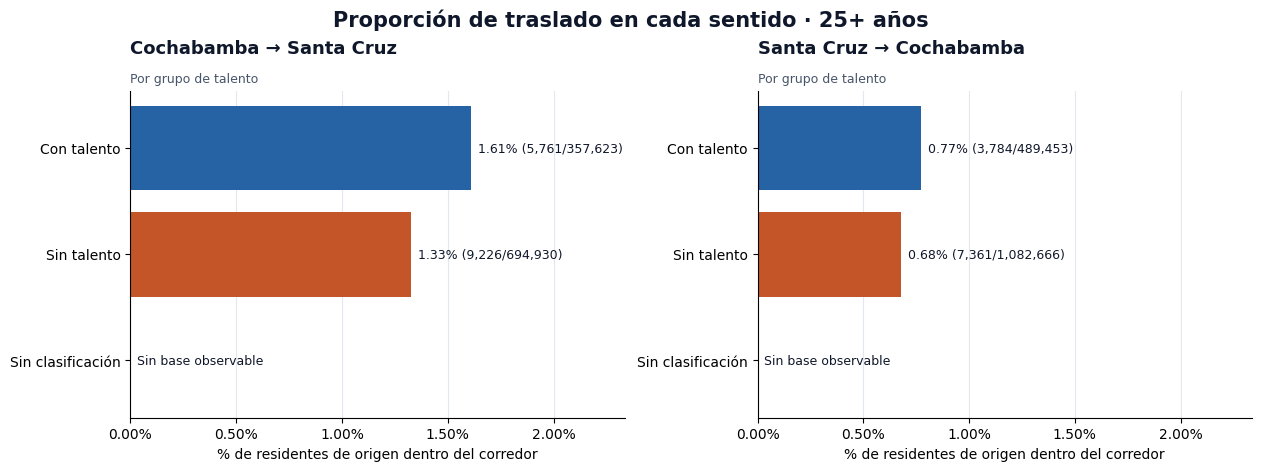

In [ ]:
# Tasas en paneles con la misma escala. El texto muestra numerador y denominador.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharex=True, layout='constrained')
talent_colors = ['#2563a5', '#c45528', '#64748b']
xmax = rates.tasa_corredor_pct.max()
for cod, ax in zip(DEPS, axes):
    p = rates[rates.origen_cod.eq(cod)].set_index('grupo_talento').loc[list(TALENT)]
    vals = p.tasa_corredor_pct.fillna(0)
    bars = ax.barh(p.etiqueta_talento, vals, color=talent_colors)
    labels = [f'{v:.2f}% ({num:,}/{den:,})' if den else 'Sin base observable'
              for v, num, den in zip(vals, p.n_cruces, p.n_corredor)]
    ax.bar_label(bars, labels=labels, padding=5, fontsize=9)
    ax.invert_yaxis()
    ax.grid(axis='x')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlim(0, max(.5, xmax * 1.45))
    ax.set_xlabel('% de residentes de origen dentro del corredor')
    heading(ax, p.ruta.iloc[0], 'Por grupo de talento')
fig.suptitle(f'Proporción de traslado en cada sentido · {EDAD_MINIMA_2024}+ años', fontsize=15, fontweight='bold')
save_show(fig, 'migration_rates_by_origin_and_talent.png')

## 3. Calidad y perfiles de movilidad

Las distribuciones y los perfiles combinan ambos orígenes y todos los grupos de talento, y distinguen: **mismo departamento** o **traslado en el corredor**. Para comparar la propensión a trasladarse entre Cochabamba y Santa Cruz, usa las tasas separadas por origen de la sección anterior. Las celdas del EDA mantienen las etiquetas censales y no cambian los datos originales.

In [ ]:
class_balance = con.execute('''
    SELECT migracion_corredor, count(*) AS n, 100.0 * count(*) / sum(count(*)) OVER() AS pct
    FROM cohort GROUP BY 1 ORDER BY 1
''').df()
class_balance['grupo_movilidad'] = class_balance.migracion_corredor.map(DEST)
target_n = class_balance.set_index('migracion_corredor').n
class_balance.to_csv(OUT / 'class_balance.csv', index=False)
display(class_balance[['grupo_movilidad', 'n', 'pct']])

raw, quality = {}, []
for col in [c for c in TITLES if c in selected]:
    # Solo se traen frecuencias agregadas de DuckDB.
    q = con.execute(f'''SELECT migracion_corredor, {col} AS value, count(*) AS n
                        FROM cohort GROUP BY 1, 2 ORDER BY 1, 2''').df()
    q['grupo_movilidad'] = q.migracion_corredor.map(DEST)
    q['share_within_target_pct'] = 100 * q.n / q.migracion_corredor.map(target_n)
    raw[col] = q
    for target, part in q.groupby('migracion_corredor'):
        code_missing = NONRESPONSE.get(col)
        n = int(target_n.loc[target])
        nulls = int(part.loc[part.value.isna(), 'n'].sum())
        unspecified = int(part.loc[part.value.map(normalize_code).eq(code_missing), 'n'].sum()) if code_missing else 0
        quality.append({'variable': col, 'nombre_variable': TITLES[col], 'migracion_corredor': int(target),
                        'grupo_movilidad': DEST[target], 'n': n, 'nulls': nulls, 'unspecified': unspecified,
                        'null_pct': 100 * nulls / n, 'unspecified_pct': 100 * unspecified / n})
missing = pd.DataFrame(quality)
missing.to_csv(OUT / 'missingness.csv', index=False)
ranges = con.execute('''
    SELECT min(p26_edad) AS age_min, max(p26_edad) AS age_max, avg(p26_edad) AS age_mean,
           min(aestudio) AS study_min, max(aestudio) AS study_max, avg(aestudio) AS study_mean
    FROM cohort
''').df()
for prefix, ceiling in [('age', 110), ('study', 30)]:
    lo, hi = (ranges.at[0, f'{prefix}_{stat}'] for stat in ('min', 'max'))
    if pd.isna(lo) or lo < 0 or hi > ceiling:
        print(f'Revisar rango de {prefix}: mínimo={lo}, máximo={hi}.')
ranges.to_csv(OUT / 'range_checks.csv', index=False)
display(ranges)

,grupo_movilidad,n,pct
0,Mismo departamento,2598540,99.004371
1,Traslado en el corredor,26132,0.995629


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,age_min,age_max,age_mean,study_min,study_max,study_mean
0,25,100,44.636969,0.0,23.0,10.345448


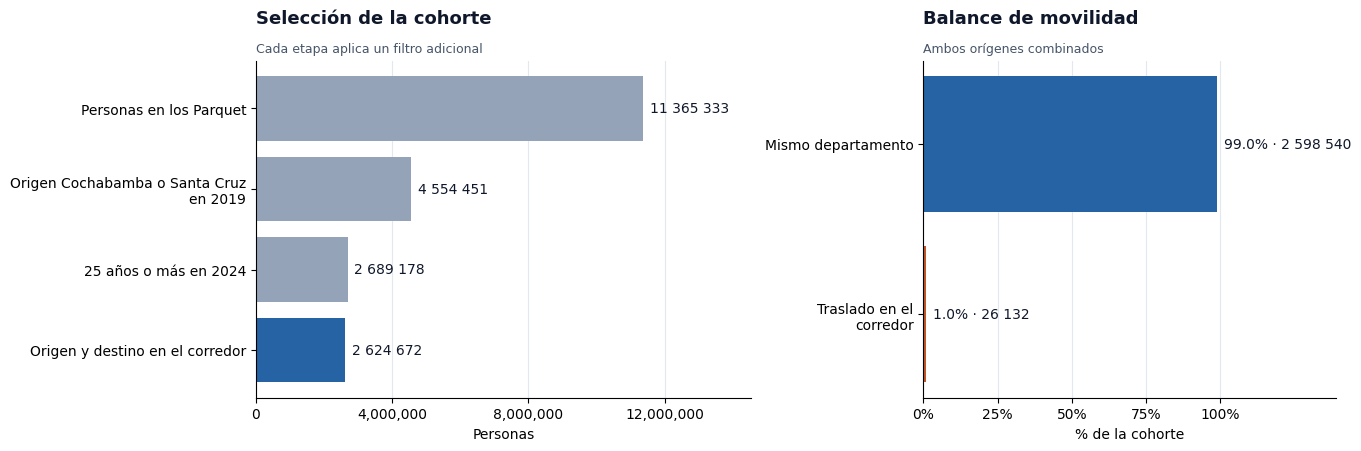

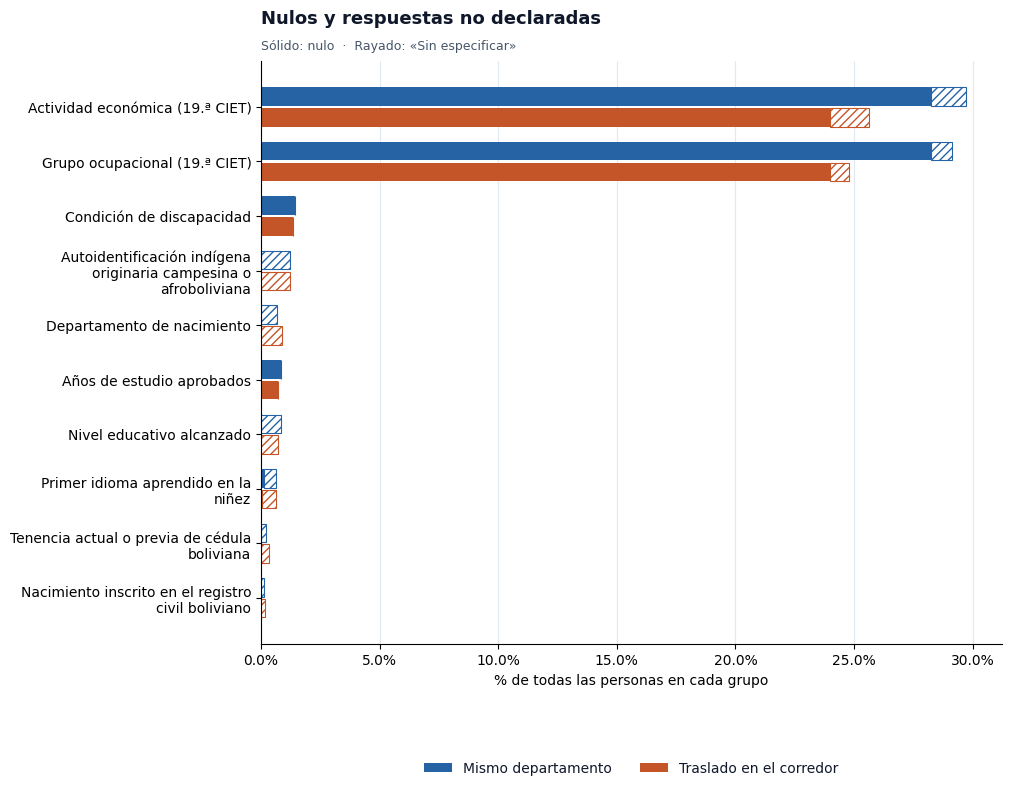

In [ ]:
fig, (ax_f, ax_b) = plt.subplots(1, 2, figsize=(13.5, 4.4), layout='constrained',
                                gridspec_kw={'width_ratios': [1.2, 1]})
names = funnel.etapa.tolist()
bars = ax_f.barh([fill(x, 32) for x in names], funnel.n, color=['#94a3b8'] * (len(names) - 1) + ['#2563a5'])
ax_f.bar_label(bars, labels=[f'{n:,}'.replace(',', ' ') for n in funnel.n], padding=5)
ax_f.set(xlabel='Personas', xlim=(0, funnel.n.max() * 1.28))
ax_f.xaxis.set_major_locator(MaxNLocator(4))
ax_f.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
heading(ax_f, 'Selección de la cohorte', 'Cada etapa aplica un filtro adicional')

bars = ax_b.barh([fill(x, 19) for x in class_balance.grupo_movilidad], class_balance.pct,
                 color=class_balance.migracion_corredor.map(COLORS))
ax_b.bar_label(bars, labels=[f'{p:.1f}% · {n:,}'.replace(',', ' ') for p, n in zip(class_balance.pct, class_balance.n)],
               padding=5)
ax_b.set(xlabel='% de la cohorte', xlim=(0, 139), xticks=[0, 25, 50, 75, 100])
ax_b.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
heading(ax_b, 'Balance de movilidad', 'Ambos orígenes combinados')
for ax in (ax_f, ax_b):
    ax.invert_yaxis()
    ax.grid(axis='x')
save_show(fig, 'validation_overview.png')

affected = missing.assign(total_pct=missing.null_pct + missing.unspecified_pct)
affected = affected.groupby('variable').total_pct.max().loc[lambda x: x > 0].sort_values(ascending=False)
if not affected.empty:
    pos = np.arange(len(affected))
    fig, ax = plt.subplots(figsize=(10, max(3.5, 2 + .58 * len(pos))), layout='constrained')
    for target, offset in [(0, -.19), (1, .19)]:
        p = missing[missing.migracion_corredor.eq(target)].set_index('variable').reindex(affected.index, fill_value=0)
        ax.barh(pos + offset, p.null_pct, height=.34, color=COLORS[target], label=DEST[target])
        ax.barh(pos + offset, p.unspecified_pct, left=p.null_pct, height=.34, color='white',
                edgecolor=COLORS[target], hatch='////', linewidth=.8)
    ax.set_yticks(pos, [fill(TITLES[c], 34) for c in affected.index])
    ax.invert_yaxis()
    ax.set_xlabel('% de todas las personas en cada grupo')
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis='x')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.18), ncol=2)
    heading(ax, 'Nulos y respuestas no declaradas', 'Sólido: nulo  ·  Rayado: «Sin especificar»')
    save_show(fig, 'missingness_by_destination.png')
else:
    print('No se observaron nulos ni códigos de no declaración.')

### Distribuciones de edad y años de estudio

Los dos grupos comparten intervalos y escalas dentro de cada figura. La edad se agrupa en intervalos de cinco años. Los años de estudio se muestran con una barra por año aprobado si los valores son enteros, o con intervalos de un año si aparecen fracciones. Aquí el denominador incluye solo **valores numéricos disponibles** en cada grupo.

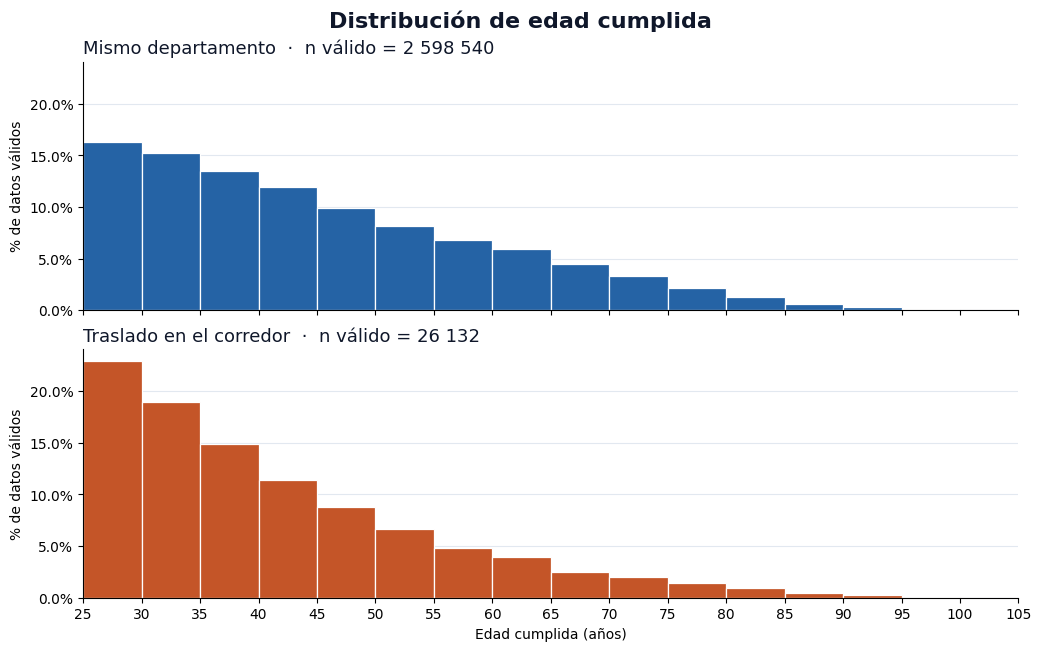

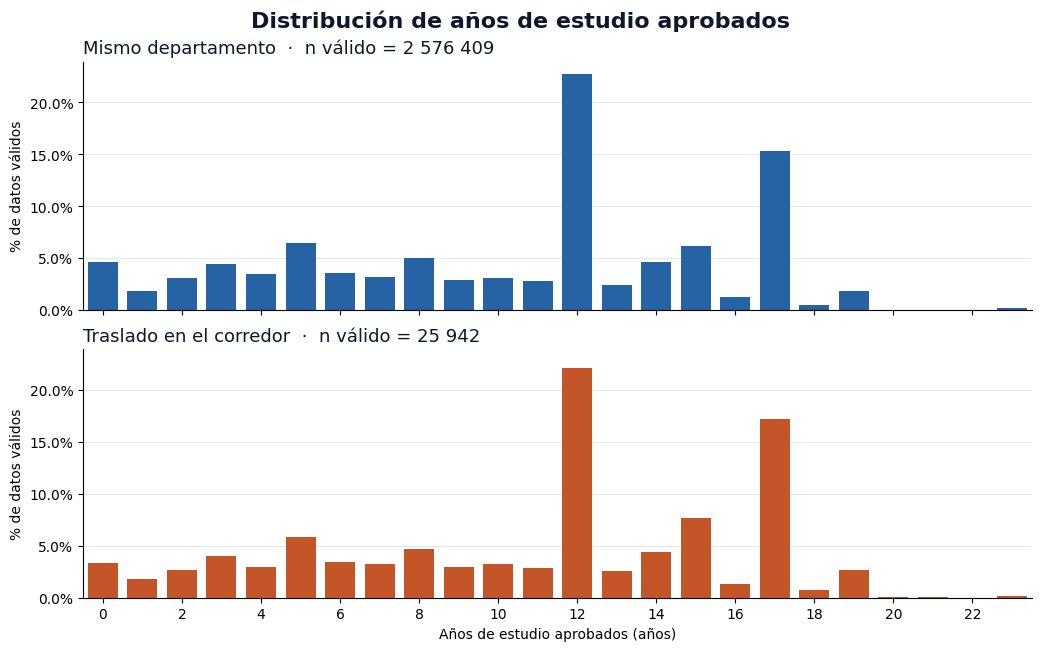

In [ ]:
def quantitative(col, value_name, export_name, figure_name, step, discrete=False):
    q = raw[col].rename(columns={'value': value_name}).copy()
    values = pd.to_numeric(q[value_name], errors='coerce').astype(float)
    valid = np.isfinite(values)
    valid_n = q.loc[valid].groupby('migracion_corredor').n.sum()
    q['share_within_valid_pct'] = (100 * q.n / q.migracion_corredor.map(valid_n)).where(valid)
    q.to_csv(OUT / export_name, index=False)
    if not valid.any():
        print(f'{TITLES[col]}: sin datos numéricos disponibles.')
        return
    v = values.loc[valid]
    discrete = discrete and np.equal(v, np.floor(v)).all()
    if discrete:
        support = np.arange(int(v.min()), int(v.max()) + 1)
        edges = np.r_[support - .5, support[-1] + .5]
    else:
        start = step * np.floor(v.min() / step)
        end = step * (np.floor(v.max() / step) + 1)
        edges = np.arange(start, end + step / 2, step)

    fig, axes = plt.subplots(2, 1, figsize=(10.3, 6.4), sharex=True, sharey=True, layout='constrained')
    for target, ax in zip(DEST, axes):
        mask = valid & q.migracion_corredor.eq(target)
        counts, _ = np.histogram(values[mask], bins=edges, weights=q.loc[mask, 'n'])
        assert counts.sum() == valid_n.get(target, 0)
        if counts.sum():
            pct = 100 * counts / counts.sum()
            if discrete:
                ax.bar(support, pct, width=.76, color=COLORS[target])
            else:
                ax.bar(edges[:-1], pct, width=np.diff(edges), align='edge',
                       color=COLORS[target], edgecolor='white', linewidth=.9)
        else:
            ax.text(.5, .5, 'Sin datos numéricos disponibles', ha='center', transform=ax.transAxes)
        ax.set_title(f'{DEST[target]}  ·  n válido = {int(counts.sum()):,}'.replace(',', ' '), loc='left')
        ax.set_ylabel('% de datos válidos')
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.grid(axis='y')
    ticks = support if discrete else edges
    axes[-1].set_xticks(ticks if len(ticks) <= 23 else ticks[::2])
    axes[-1].set_xlim(edges[0], edges[-1])
    axes[-1].set_xlabel(f'{TITLES[col]} (años)')
    fig.suptitle(f'Distribución de {TITLES[col].lower()}', fontweight='bold', fontsize=16)
    save_show(fig, figure_name)

quantitative('p26_edad', 'age', 'age_distribution.csv', 'age_histogram.png', step=5)
quantitative('aestudio', 'years_study', 'study_distribution.csv', 'study_distribution.png', step=1, discrete=True)

### Perfiles categóricos por grupo de movilidad

Cada barra indica qué proporción de un grupo de movilidad pertenece a la categoría. No es la probabilidad de trasladarse dada esa categoría. Cuando hay más de 12 categorías etiquetadas, se agrupan las menos frecuentes y el CSV mantiene el detalle. Los porcentajes incluyen en el denominador las categorías nulas y no declaradas.

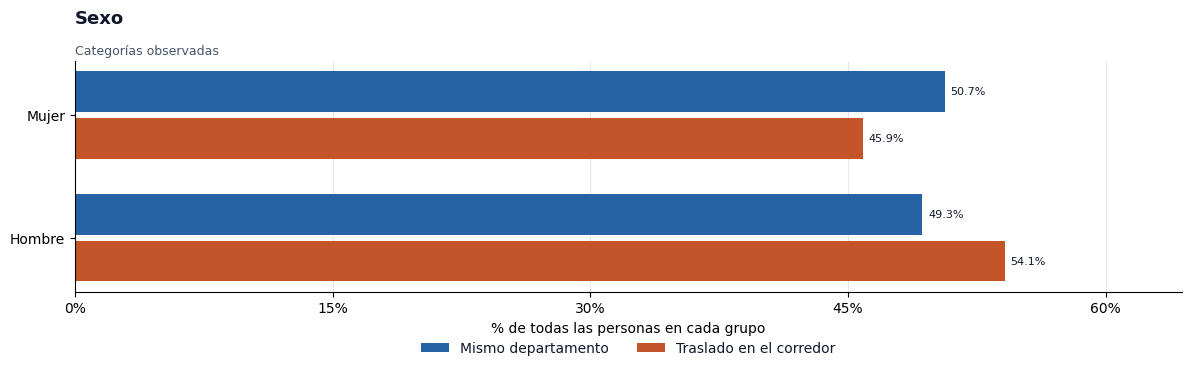

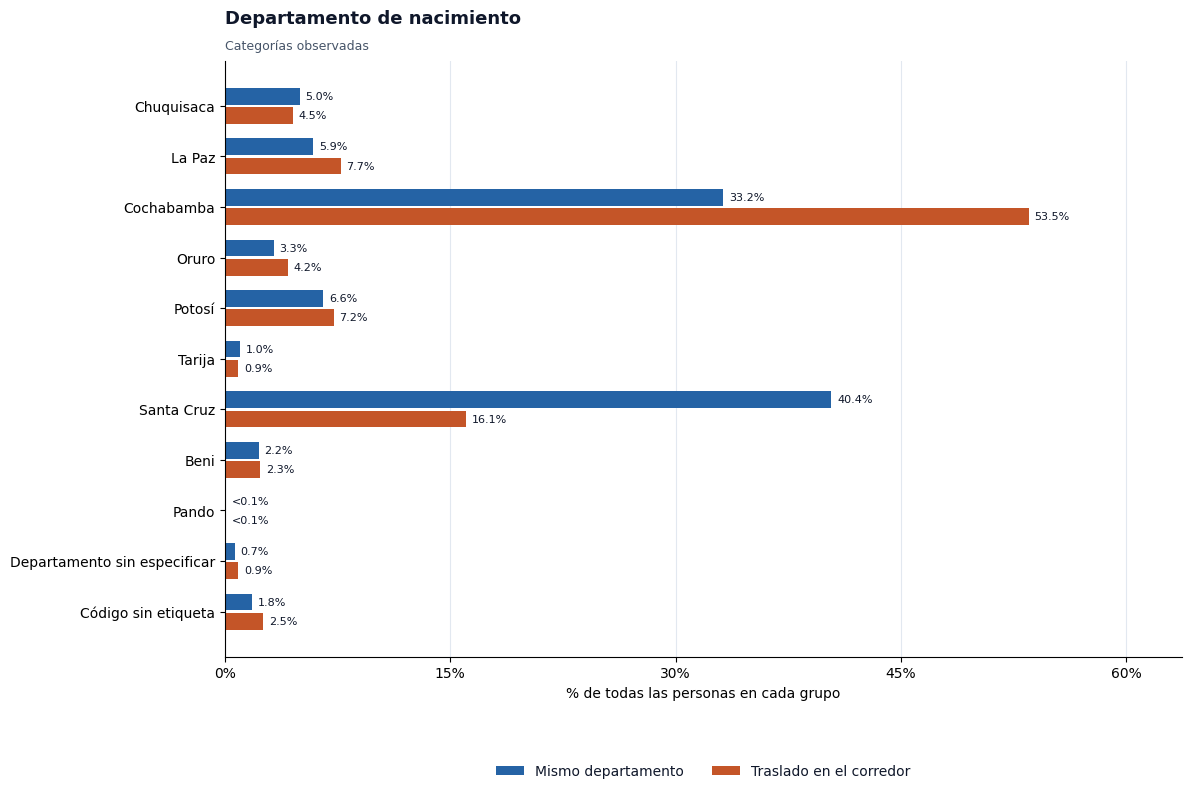

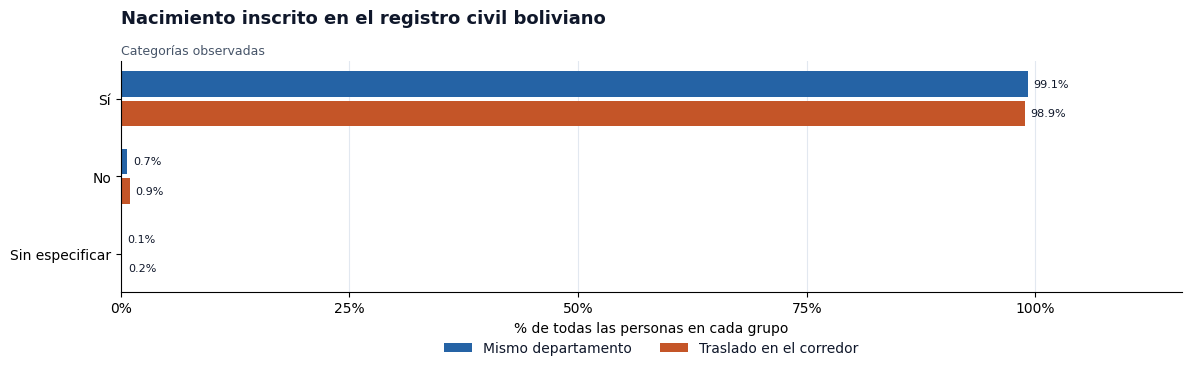

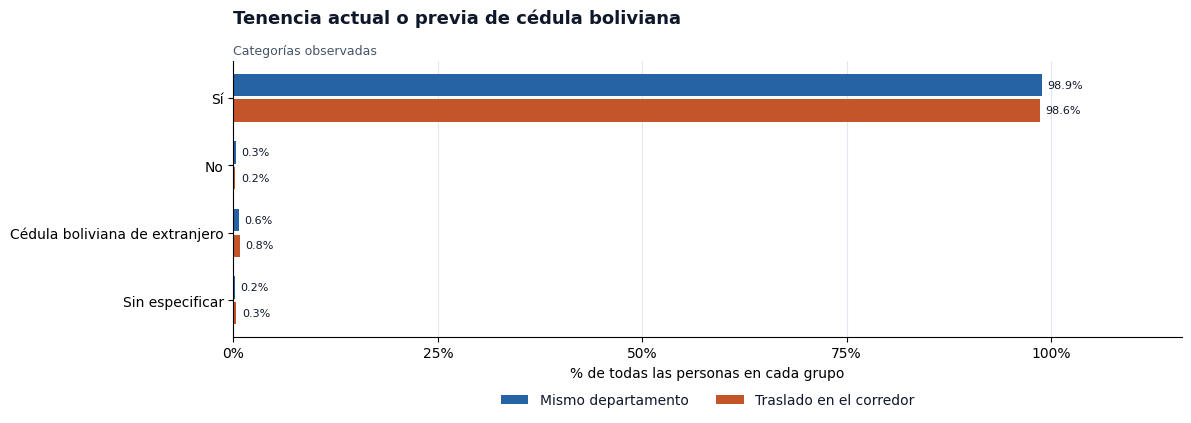

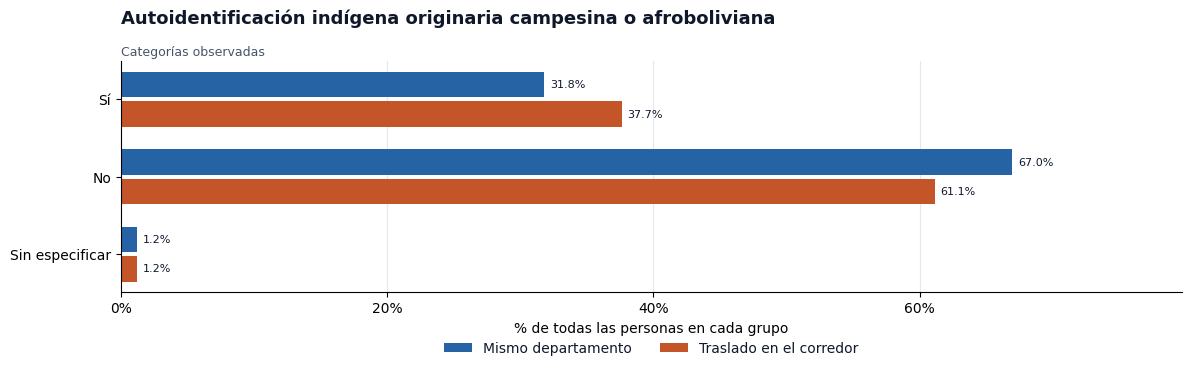

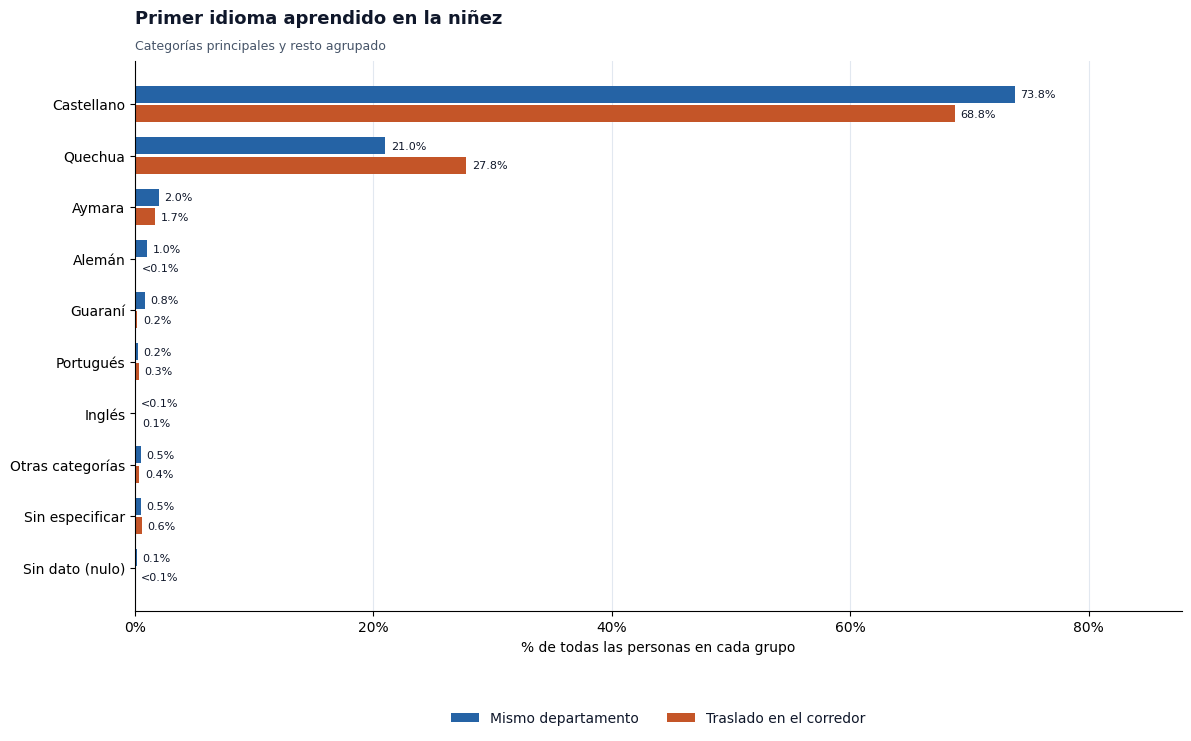

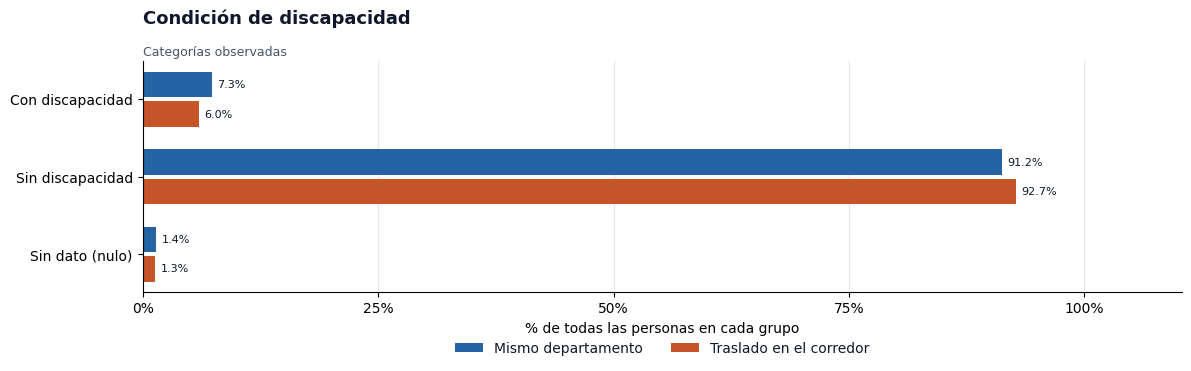

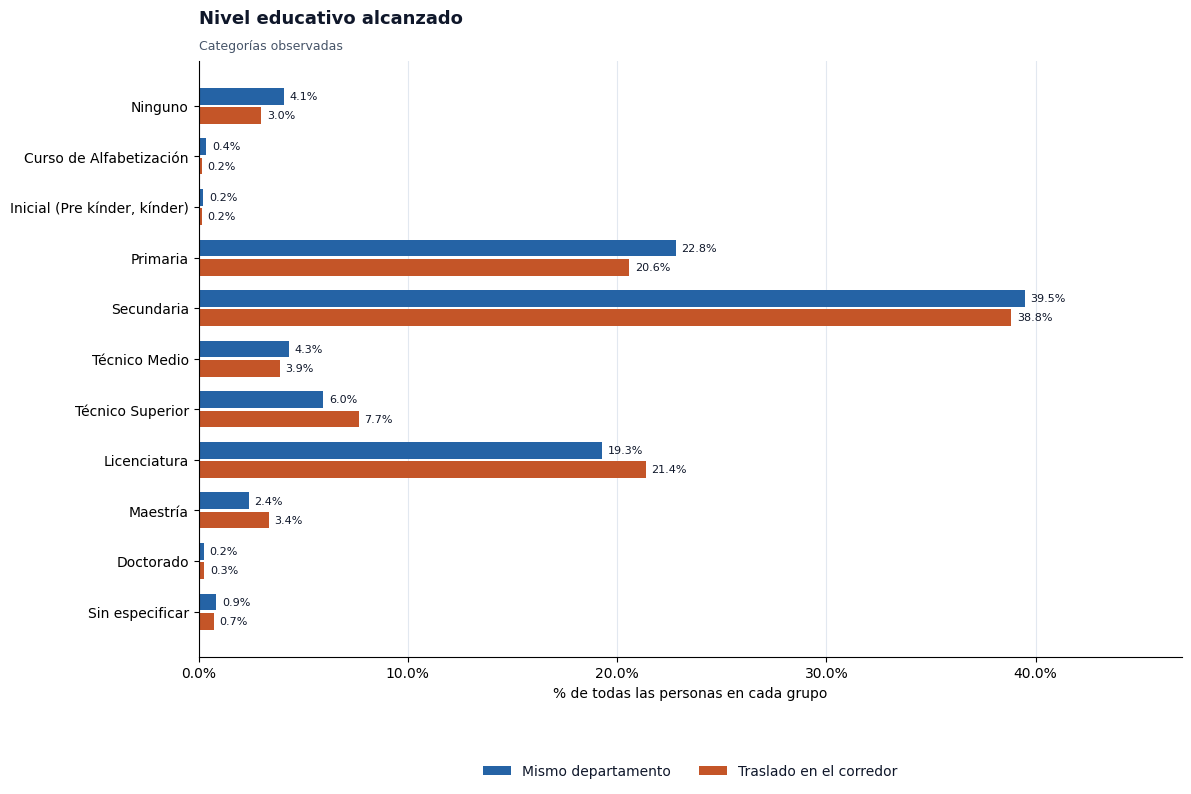

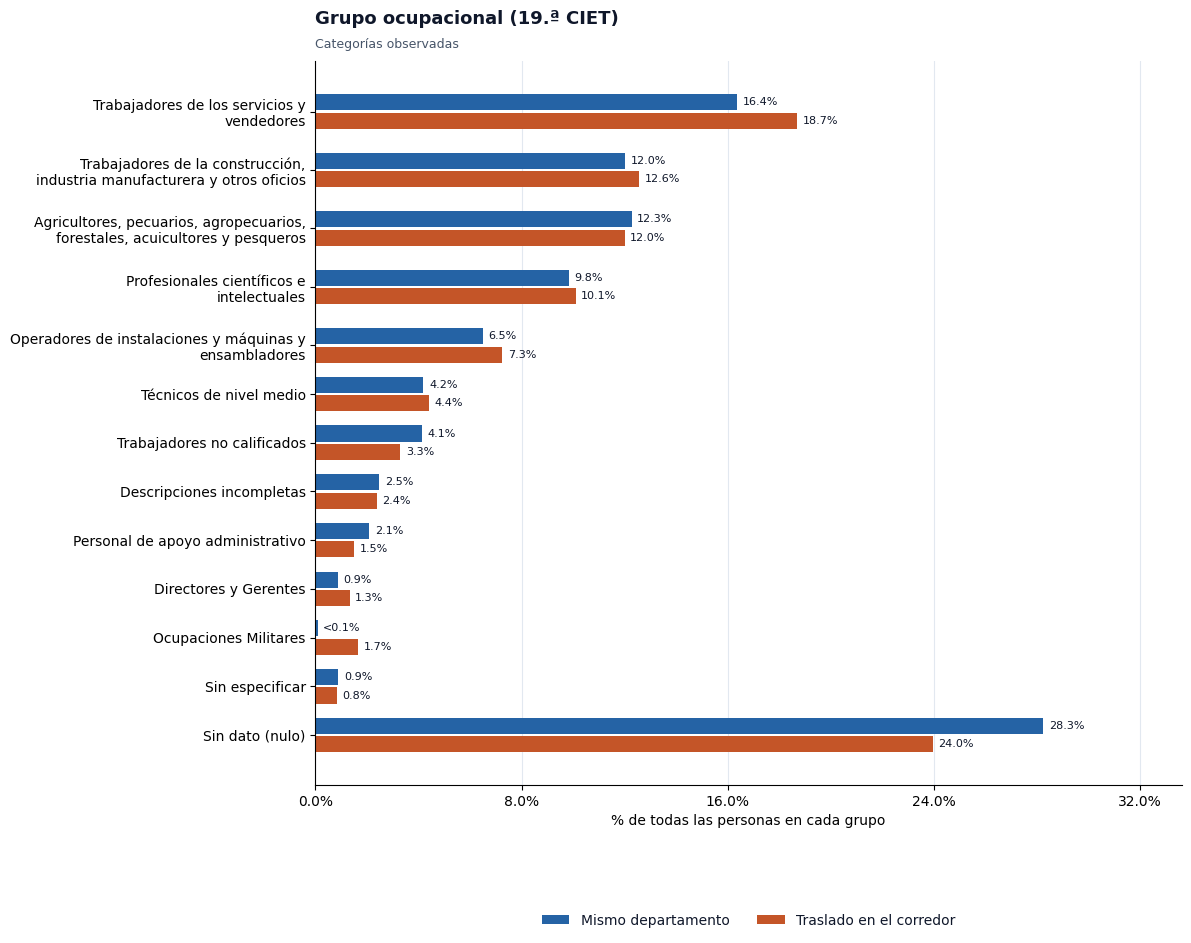

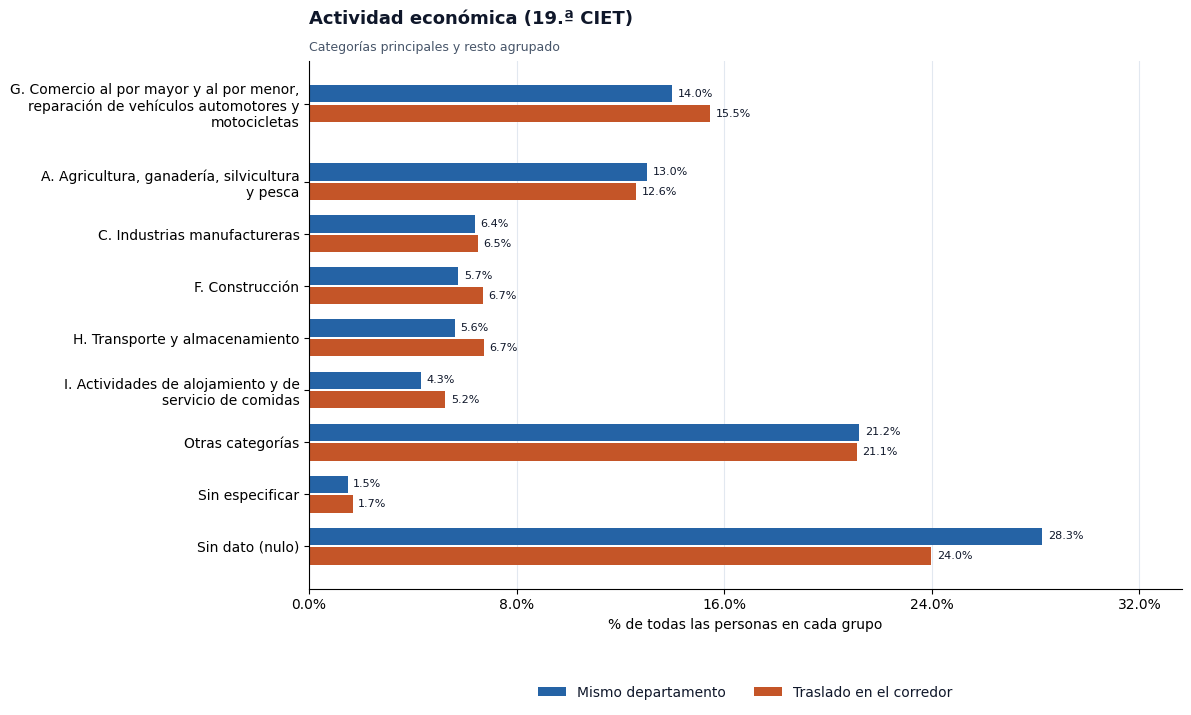

Códigos sin etiqueta confirmada; consulta unmapped_category_codes.csv.


,variable,category_code,grupo_movilidad,n
0,dep_nac_cod,0,Mismo departamento,46401
1,dep_nac_cod,0,Traslado en el corredor,666


In [ ]:
def categorical_profile(col):
    q = raw[col].copy()
    q['category_code'] = q.value.map(normalize_code)
    q['category_label'] = q.category_code.map(CATEGORY_LABELS[col])
    q['label_status'] = np.select(
        [q.value.isna(), q.category_label.isna(), q.category_code.eq(NONRESPONSE.get(col))],
        ['nulo', 'sin_catálogo', 'sin_especificar'], default='etiquetado')
    q.loc[q.label_status.eq('nulo'), 'category_label'] = NULL
    unknown = q.label_status.eq('sin_catálogo')
    q.loc[unknown, 'category_label'] = UNKNOWN + ' (' + q.loc[unknown, 'category_code'].astype(str) + ')'
    pcols = ['migracion_corredor', 'grupo_movilidad', 'category_code', 'category_label',
             'label_status', 'n', 'share_within_target_pct']
    q[pcols].to_csv(OUT / ('sex_distribution.csv' if col == 'p25_sexo' else f'profile_{col}.csv'), index=False)

    valid = q[q.label_status.eq('etiquetado')]
    keep = set(valid.category_label)
    if len(keep) > 12:
        ranked = valid.groupby(['migracion_corredor', 'category_label'], as_index=False).n.sum()
        top = (ranked.sort_values(['n', 'category_label'], ascending=[False, True])
                     .groupby('migracion_corredor', sort=False).head(6))
        keep = set(top.category_label)
    q['display_label'] = q.category_label
    q.loc[unknown, 'display_label'] = UNKNOWN
    q.loc[q.label_status.eq('etiquetado') & ~q.category_label.isin(keep), 'display_label'] = OTHER
    plot = (q.groupby(['display_label', 'migracion_corredor']).share_within_target_pct.sum()
             .unstack(fill_value=0).reindex(columns=DEST, fill_value=0))
    assert np.allclose(plot.sum(axis=0), [100 if t in target_n.index else 0 for t in DEST]), col
    if col in ORDERED:
        order = [v for k, v in sorted(CATEGORY_LABELS[col].items(), key=lambda kv: int(kv[0])) if v in keep]
    else:
        order = sorted(keep, key=lambda v: (-plot.loc[v].mean(), v))
    not_stated = CATEGORY_LABELS[col].get(NONRESPONSE.get(col))
    order += [v for v in [OTHER, not_stated, NULL, UNKNOWN] if v in plot.index and v not in order]
    assert len(order) == len(plot)
    wrapped = [fill(x, width=40) for x in order]
    pos = np.r_[0., np.cumsum([max(1., .30 * (a.count('\n') + b.count('\n') + 2))
                                for a, b in zip(wrapped, wrapped[1:])])]
    fig, ax = plt.subplots(figsize=(11.8, max(3.6, 2.0 + .53 * (pos[-1] + 1))),
                           layout='constrained')
    for target, offset in [(0, -.19), (1, .19)]:
        pct = plot.loc[order, target].to_numpy()
        bars = ax.barh(pos + offset, pct, height=.33, color=COLORS[target], label=DEST[target])
        ax.bar_label(bars, labels=['' if p == 0 else '<0.1%' if p < .1 else f'{p:.1f}%' for p in pct],
                     padding=4, fontsize=8)
    xmax = float(plot.max().max())
    ax.set_xlim(0, min(116, xmax * 1.19))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, prune='upper'))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlabel('% de todas las personas en cada grupo')
    ax.set_yticks(pos, wrapped)
    ax.invert_yaxis()
    ax.grid(axis='x')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.16), ncol=2)
    heading(ax, TITLES[col], 'Categorías principales y resto agrupado' if OTHER in plot.index else 'Categorías observadas')
    save_show(fig, f'profile_{col}.png')
    return q.loc[unknown, pcols].assign(variable=col)

categorical = [c for c in CATEGORY_LABELS if c in raw]
audit = pd.concat([categorical_profile(c) for c in categorical], ignore_index=True)
audit.to_csv(OUT / 'unmapped_category_codes.csv', index=False)
if not audit.empty:
    print('Códigos sin etiqueta confirmada; consulta unmapped_category_codes.csv.')
    display(audit[['variable', 'category_code', 'grupo_movilidad', 'n']])
else:
    print('Todos los códigos categóricos observados tienen una etiqueta confirmada.')

## 4. Preparación para un análisis posterior

La variable migracion_corredor vale 1 si cambió de departamento dentro del par, y 0 si terminó en el mismo departamento. La etiqueta is_talent no se redefine. Para comparar la movilidad con y sin talento, conviene separar o controlar el origen de 2019. Si is_talent se construyó con educación u ocupación observadas en 2024, puede reflejar cambios posteriores al traslado. Lo mismo vale para otras covariables medidas después de 2019. Un modelo con estas variables puede encontrar asociaciones, pero no identificar por sí solo las causas de la migración.

In [ ]:
if EXPORTAR_COHORTE_PARQUET:
    # Conserva la etiqueta y covariables. No incluye la clave directa geo-vivienda
    # ni el objetivo unidireccional antiguo.
    omit = {'i00'}
    export_cols = ', '.join('"' + c.replace('"', '""') + '"' for c in cohort_schema.column_name if c.lower() not in omit)
    path_sql = str(OUT/f'cohorte_corredor_cbb_scz_{EDAD_MINIMA_2024}mas.parquet').replace("'", "''")
    con.execute(f"COPY (SELECT {export_cols} FROM cohort) TO '{path_sql}' (FORMAT PARQUET, COMPRESSION ZSTD)")

def records(df):
    return json.loads(df.to_json(orient='records'))

report = {
    'scope': 'Corredor bilateral Cochabamba ↔ Santa Cruz: origen 2019 y destino 2024 dentro de ambos departamentos, sin filtro de talento.',
    'age_cut': {'column': 'p26_edad', 'reference_year': 2024, 'min_inclusive': EDAD_MINIMA_2024},
    'age_cut_audit': records(age_audit),
    'outcome': DEST,
    'input_parquet_files': len(PARQUETS),
    'profile_columns': selected,
    'funnel': records(funnel),
    'input_coverage': records(coverage),
    'flow_summary': records(flow_summary),
    'rates': records(rates),
    'bilateral_balance': records(balance),
    'range_checks': records(ranges),
    'class_balance': records(class_balance),
    'unmapped_category_codes': len(audit[['variable', 'category_code']].drop_duplicates()),
    'limitations': ['Cobertura sujeta a filtros previos del ZIP.',
                    'El corte de edad no identifica si la mudanza ocurrió con la familia.',
                    'El saldo solo compara el corredor bilateral y no cuantifica fuga de talentos total.',
                    'El censo compara dos puntos de residencia y no registra todos los movimientos intermedios.',
                    'Las asociaciones con variables de 2024, incluido aestudio, no identifican causas ni predisposición previa al traslado.',
                    'Con 10 remuestreos bootstrap solo se describen diagnósticos exploratorios de estabilidad; no se reportan IC ni p-valores bootstrap.'],
}
(OUT/'eda_validation_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
# El ZIP definitivo se genera al final, después de los modelos y sus diagnósticos.

8284

In [ ]:
from scipy.special import expit
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed
from tqdm.auto import trange

SEED = 2024
MAX_MODEL_N = 300_000
N_BOOT = 200  # Réplicas por vivienda para intervalos percentiles y estabilidad.
N_BOOT_TREE = N_BOOT
N_BOOT_TEST = N_BOOT
MIN_CATEGORY_SHARE = 0.01
CLUSTER_COL = 'i00'
EXCLUDED = {'p41a_nivel_act', 'ocu_1d_19', 'act_eco_2d_19', 'grupo_talento'}
AGE_EDGES = [25, 30, 35, 40, 45, 50, 55, 60, 65, np.inf]
AGE_LABELS = ['25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65+']

LABELS = {**CATEGORY_LABELS, 'grupo_talento': TALENT}
SHORT = {'p25_sexo': 'sexo', 'dep_nac_cod': 'nacimiento', 'p28_cn': 'cn_inscrito', 'p29_ci': 'cedula',
         'p32_pueblo_per': 'autoid_indigena', 'p341_idiomat_cod': 'idioma', 'p42_discap': 'discapacidad',
         'p41a_nivel_act': 'nivel', 'ocu_1d_19': 'ocupacion', 'act_eco_2d_19': 'actividad',
         'grupo_talento': 'talento'}
available = set(cohort_schema.column_name)
MODEL_CATEGORICAL = [c for c in [*CATEGORY_LABELS, 'grupo_talento'] if c in available and c not in EXCLUDED]
use_cluster = CLUSTER_COL in available

n_cohort = con.execute('SELECT count(*) FROM cohort').fetchone()[0]
share = min(1.0, MAX_MODEL_N / n_cohort)
columns = ['migracion_corredor', 'dep_res5_cod', 'p26_edad', 'aestudio', *MODEL_CATEGORICAL]
if use_cluster:
    columns.append(CLUSTER_COL)
    cluster_key = f"hash(CAST({CLUSTER_COL} AS VARCHAR) || '|{SEED}') % 1000000"
    where = f'{CLUSTER_COL} IS NOT NULL' + (f' AND {cluster_key} < {int(share * 1_000_000)}' if share < 1 else '')
    query = f'SELECT {", ".join(columns)} FROM cohort WHERE {where}'
else:
    sample = f' USING SAMPLE {share * 100:.4f}% (bernoulli, {SEED})' if share < 1 else ''
    query = f'SELECT {", ".join(columns)} FROM cohort{sample}'
raw_df = con.execute(query).df()

for col in ['p26_edad', 'aestudio']:
    raw_df[col] = pd.to_numeric(raw_df[col], errors='coerce')
complete = raw_df[['p26_edad', 'aestudio']].notna().all(axis=1)
df = raw_df[complete].reset_index(drop=True)
y = df.migracion_corredor.to_numpy(dtype=int)
groups = pd.factorize(df[CLUSTER_COL])[0] if use_cluster else np.arange(len(df))
print(f'Cohorte: {n_cohort:,} · muestra de modelado: {len(raw_df):,} · excluidos por edad o años de estudio nulos: {(~complete).sum():,}')
print(f'Unidad de remuestreo: {"vivienda (" + CLUSTER_COL + ")" if use_cluster else "persona"} · {groups.max() + 1:,} unidades')
print(f'Eventos: {y.sum():,} ({100 * y.mean():.2f}%)')


def label_series(frame, col):
    labels = frame[col].map(normalize_code).map(LABELS[col]).fillna(UNKNOWN)
    return labels.where(frame[col].notna(), NULL)


def collapse_rare(series, min_share):
    freq = series.value_counts(normalize=True)
    return series.where(series.map(freq) >= min_share, OTHER)


def dummies(series, prefix, references):
    series = series.astype(str).str.slice(0, 30)
    reference = series.value_counts().idxmax()
    references[prefix] = reference
    return pd.get_dummies(series, prefix=prefix, prefix_sep='=', dtype=float).drop(columns=f'{prefix}={reference}')


def design_matrix(frame, continuous_age=False):
    references, parts = {}, []
    age = frame.p26_edad.astype(float) - 5
    if continuous_age:
        parts.append(age.rename('edad_2019'))
    else:
        centred = (age - age.mean()) / 10
        parts.extend([centred.rename('edad_2019'), (centred ** 2).rename('edad_2019^2')])
    parts.append(frame.aestudio.astype(float).rename('aestudio'))
    parts.append((frame.dep_res5_cod == 7).astype(float).rename('origen=Santa Cruz'))
    for col in MODEL_CATEGORICAL:
        parts.append(dummies(collapse_rare(label_series(frame, col), MIN_CATEGORY_SHARE), SHORT[col], references))
    return pd.concat(parts, axis=1), references


X_frame, references = design_matrix(df)
names = ['const', *X_frame.columns]
X = np.column_stack([np.ones(len(df)), X_frame.to_numpy(dtype=float)])
print(f'Parámetros: {X.shape[1]} · eventos por parámetro (EPV): {y.sum() / X.shape[1]:.0f}')
print('Categorías de referencia:', references)

corr = np.corrcoef(X[:, 1:], rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=names[1:]).sort_values(ascending=False)
print('\nFactores de inflación de la varianza más altos:')
display(vif.head(8).round(2).to_frame('VIF'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Cohorte: 2,624,672 · muestra de modelado: 297,202 · excluidos por edad o años de estudio nulos: 2,516
Unidad de remuestreo: vivienda (i00) · 158,082 unidades
Eventos: 2,934 (1.00%)
Parámetros: 24 · eventos por parámetro (EPV): 122
Categorías de referencia: {'sexo': 'Mujer', 'nacimiento': 'Santa Cruz', 'cn_inscrito': 'Sí', 'cedula': 'Sí', 'autoid_indigena': 'No', 'idioma': 'Castellano', 'discapacidad': 'Sin discapacidad'}

Factores de inflación de la varianza más altos:


,VIF
cedula=Otras categorías,4.67
cn_inscrito=Otras categorías,4.42
nacimiento=Cochabamba,3.07
origen=Santa Cruz,2.45
idioma=Quechua,1.89
edad_2019,1.69
nacimiento=Código sin etiqueta,1.61
edad_2019^2,1.52


In [ ]:
from sklearn.linear_model import LogisticRegression

METRICS = ['AUC-ROC', 'Precisión promedio (AP)', 'Brier']

_model = LogisticRegression(C=np.inf, fit_intercept=False, solver='lbfgs',
                            max_iter=1000, tol=1e-6, warm_start=True)


def fit_logit(X, y, weights=None, start=None):
    _model.coef_ = np.zeros((1, X.shape[1])) if start is None else start[None, :].copy()
    _model.fit(X, y, sample_weight=weights)
    return _model.coef_[0].copy(), bool(_model.n_iter_[0] < _model.max_iter)


def performance(y, p, weights=None):
    return np.array([roc_auc_score(y, p, sample_weight=weights),
                     average_precision_score(y, p, sample_weight=weights),
                     brier_score_loss(y, p, sample_weight=weights)])


def cluster_weights(rng, groups):
    n_groups = groups.max() + 1
    return np.bincount(rng.integers(0, n_groups, n_groups), minlength=n_groups)[groups].astype(float)


def bootstrap_logit(X, y, groups, n_boot, seed):
    rng = np.random.default_rng(seed)
    beta_hat, converged = fit_logit(X, y)
    apparent = performance(y, expit(X @ beta_hat))
    coefs = np.empty((n_boot, X.shape[1]))
    optimism = np.empty((n_boot, len(METRICS)))
    ok = np.zeros(n_boot, dtype=bool)
    oob_sum, oob_n = np.zeros(len(y)), np.zeros(len(y))
    for b in trange(n_boot):
        w = cluster_weights(rng, groups)
        keep = w > 0
        coefs[b], ok[b] = fit_logit(X[keep], y[keep], w[keep], start=beta_hat)
        p_b = expit(X @ coefs[b])
        apparent_b = performance(y, p_b, w)
        test_b = performance(y, p_b)
        # AUC/AP: mayor es mejor; Brier: menor es mejor. Todas las columnas expresan optimismo positivo.
        optimism[b] = [apparent_b[0] - test_b[0], apparent_b[1] - test_b[1], test_b[2] - apparent_b[2]]
        oob = ~keep
        oob_sum[oob] += p_b[oob]
        oob_n[oob] += 1
    seen = oob_n > 0
    return {'beta': beta_hat, 'converged': converged, 'coefs': coefs[ok], 'optimism': optimism[ok],
            'apparent': apparent, 'n_failed': int((~ok).sum()), 'oob_mask': seen,
            'oob_pred': np.where(seen, oob_sum / np.maximum(oob_n, 1), np.nan)}


boot = bootstrap_logit(X, y, groups, N_BOOT, SEED)
print(f'Ajuste completo convergió: {boot["converged"]} · réplicas descartadas por no convergencia: {boot["n_failed"]} de {N_BOOT}')
print(f'Bootstrap por vivienda: {N_BOOT} réplicas. Se calcularán IC percentiles y estabilidad de signo; los p-valores por signo son aproximaciones bootstrap.')

seen = boot['oob_mask']
perf_oob = performance(y[seen], boot['oob_pred'][seen])
optimism_mean = boot['optimism'].mean(axis=0)
corrected = boot['apparent'].copy()
corrected[:2] -= optimism_mean[:2]
corrected[2] += optimism_mean[2]
perf = pd.DataFrame({'métrica': METRICS,
                     'aparente': boot['apparent'],
                     'optimismo_bootstrap': optimism_mean,
                     'corregida_por_optimismo': corrected,
                     'fuera_de_bolsa': perf_oob})
perf.to_csv(OUT / 'logit_bootstrap_performance.csv', index=False)
print(f'Referencias sin información: AP = {y.mean():.4f} · Brier = {y.mean() * (1 - y.mean()):.4f}')
display(perf.round(4))

  0%|          | 0/200 [00:00<?, ?it/s]

Ajuste completo convergió: True · réplicas descartadas por no convergencia: 0 de 200
Bootstrap por vivienda: 200 réplicas. Se calcularán IC percentiles y estabilidad de signo; los p-valores por signo son aproximaciones bootstrap.
Referencias sin información: AP = 0.0100 · Brier = 0.0099


,métrica,aparente,optimismo_bootstrap,corregida_por_optimismo,fuera_de_bolsa
0,AUC-ROC,0.6851,0.0031,0.6820,0.6815
1,Precisión promedio (AP),0.0206,0.0007,0.0199,0.0199
2,Brier,0.0098,-0.0000,0.0098,0.0098


Odds ratios respecto de las categorías de referencia impresas arriba. «aestudio» es el cambio por año adicional de estudio medido en 2024: asociación contemporánea, no predisposición ni efecto causal.


,variable,odds_ratio,or_bootstrap_mediana,or_ic95_inf,or_ic95_sup,p_bootstrap_signo_aprox,estabilidad_signo_pct,sesgo_bootstrap,ic95_excluye_1
0,nacimiento=Código sin etiqueta,4.870,4.855,3.365,6.768,0.010,100.0,-0.010,True
1,nacimiento=Cochabamba,4.516,4.545,3.601,5.366,0.010,100.0,-0.006,True
2,nacimiento=Oruro,4.381,4.374,3.302,5.357,0.010,100.0,-0.013,True
3,nacimiento=La Paz,4.139,4.139,3.392,5.190,0.010,100.0,0.001,True
4,nacimiento=Beni,3.254,3.162,2.424,4.125,0.010,100.0,-0.025,True
5,nacimiento=Otras categorías,3.154,3.148,2.410,4.008,0.010,100.0,-0.010,True
6,nacimiento=Potosí,2.967,2.924,2.374,3.629,0.010,100.0,-0.010,True
7,nacimiento=Chuquisaca,2.667,2.666,2.132,3.194,0.010,100.0,-0.006,True
8,sexo=Hombre,1.277,1.272,1.177,1.366,0.010,100.0,-0.003,True
9,cn_inscrito=Otras categorías,1.272,1.320,0.570,6.476,0.448,78.0,0.163,False


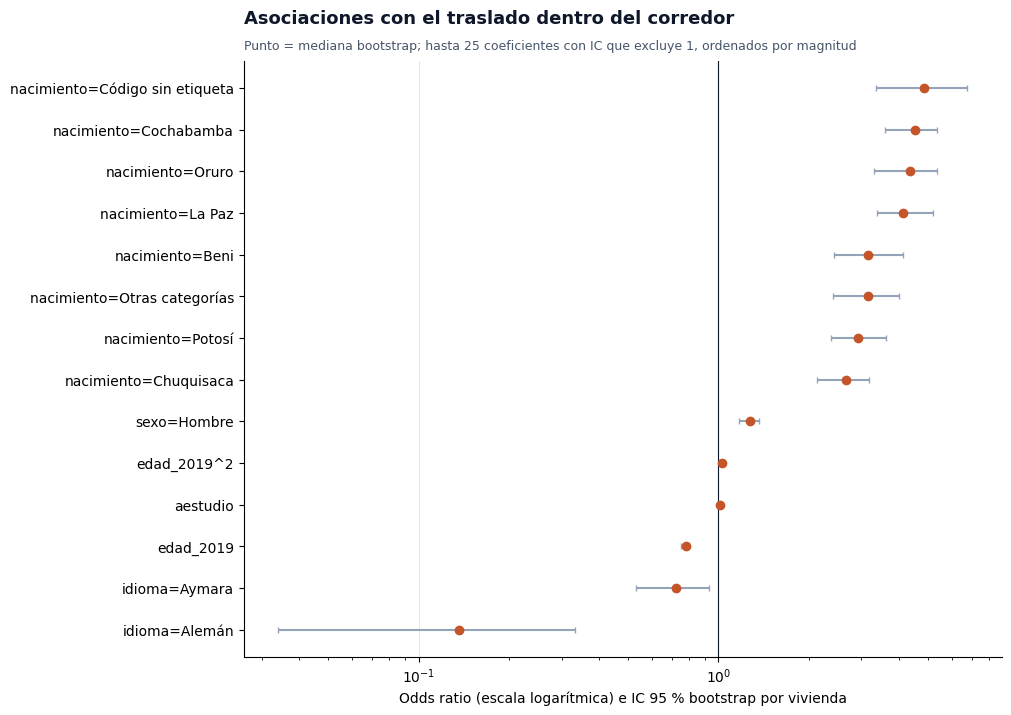

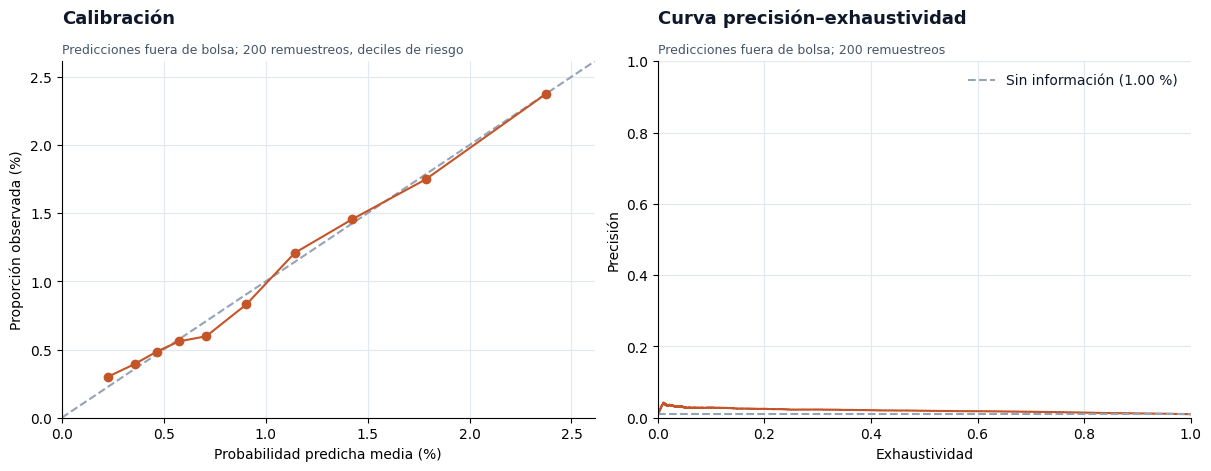

In [ ]:
coefs, beta_hat = boot['coefs'], boot['beta']
lo, hi = np.percentile(coefs, [2.5, 97.5], axis=0)
k = np.minimum((coefs > 0).sum(axis=0), (coefs < 0).sum(axis=0))
share_pos = (coefs > 0).mean(axis=0)

table = pd.DataFrame({'variable': names, 'odds_ratio': np.exp(beta_hat),
                      'or_bootstrap_mediana': np.exp(np.median(coefs, axis=0)),
                      'or_ic95_inf': np.exp(lo), 'or_ic95_sup': np.exp(hi),
                      'p_bootstrap_signo_aprox': np.minimum(1, 2 * (k + 1) / (len(coefs) + 1)),
                      'estabilidad_signo_pct': 100 * np.maximum(share_pos, 1 - share_pos),
                      'sesgo_bootstrap': coefs.mean(axis=0) - beta_hat,
                      'ic95_excluye_1': (lo > 0) | (hi < 0)}).iloc[1:]
table.to_csv(OUT / 'logit_bootstrap_odds_ratios.csv', index=False)
print('Odds ratios respecto de las categorías de referencia impresas arriba. '
      '«aestudio» es el cambio por año adicional de estudio medido en 2024: asociación contemporánea, no predisposición ni efecto causal.')
display(table.sort_values('odds_ratio', ascending=False).round(3).reset_index(drop=True))

shown = (table[table.ic95_excluye_1].assign(efecto=lambda t: np.abs(np.log(t.odds_ratio)))
         .nlargest(25, 'efecto').sort_values('odds_ratio'))
if len(shown):
    pos = np.arange(len(shown))
    fig, ax = plt.subplots(figsize=(10, .36 * len(shown) + 2), layout='constrained')
    ax.errorbar(shown.or_bootstrap_mediana, pos, xerr=[shown.or_bootstrap_mediana - shown.or_ic95_inf, shown.or_ic95_sup - shown.or_bootstrap_mediana],
                fmt='o', color=COLORS[1], ecolor='#94a3b8', capsize=2)
    ax.axvline(1, color='#0f172a', lw=.8)
    ax.set_xscale('log')
    ax.set_yticks(pos, [fill(v, 38) for v in shown.variable])
    ax.grid(axis='x')
    ax.set_xlabel('Odds ratio (escala logarítmica) e IC 95 % bootstrap por vivienda')
    heading(ax, 'Asociaciones con el traslado dentro del corredor',
            'Punto = mediana bootstrap; hasta 25 coeficientes con IC que excluye 1, ordenados por magnitud')
    save_show(fig, 'logit_odds_ratios.png')

p_oob, y_oob = boot['oob_pred'][seen], y[seen]
calib = (pd.DataFrame({'pred': p_oob, 'obs': y_oob})
         .groupby(pd.qcut(p_oob, 10, duplicates='drop'), observed=True).mean())
precision, recall, _ = precision_recall_curve(y_oob, p_oob)

fig, (ax_c, ax_p) = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
lim = 100 * max(calib.pred.max(), calib.obs.max()) * 1.1
ax_c.plot([0, lim], [0, lim], color='#94a3b8', ls='--')
ax_c.plot(100 * calib.pred, 100 * calib.obs, 'o-', color=COLORS[1])
ax_c.set(xlabel='Probabilidad predicha media (%)', ylabel='Proporción observada (%)', xlim=(0, lim), ylim=(0, lim))
ax_c.grid()
heading(ax_c, 'Calibración', f'Predicciones fuera de bolsa; {N_BOOT} remuestreos, deciles de riesgo')
ax_p.plot(recall, precision, color=COLORS[1])
ax_p.axhline(y.mean(), color='#94a3b8', ls='--', label=f'Sin información ({100 * y.mean():.2f} %)')
ax_p.set(xlabel='Exhaustividad', ylabel='Precisión', xlim=(0, 1), ylim=(0, 1))
ax_p.legend(loc='upper right')
ax_p.grid()
heading(ax_p, 'Curva precisión–exhaustividad', f'Predicciones fuera de bolsa; {N_BOOT} remuestreos')
save_show(fig, 'logit_calibration_pr.png')

,max_depth,min_samples_leaf,ap_media,ap_ee
0,3,0.002,0.0278,0.0011
1,3,0.005,0.0278,0.0011
2,3,0.010,0.0278,0.0011
3,4,0.002,0.0325,0.0018
4,4,0.005,0.0325,0.0018
5,4,0.010,0.0313,0.0014
6,5,0.002,0.0360,0.0018
7,5,0.005,0.0354,0.0015
8,5,0.010,0.0342,0.0013
9,6,0.002,0.0386,0.0021


Regla de un error estándar → max_depth=6, min_samples_leaf=0.005


  0%|          | 0/200 [00:00<?, ?it/s]

Conjunto de prueba: 98,860 personas · prevalencia 1.01 % (AP sin información = prevalencia). El árbol usa class_weight="balanced": se compara solo el orden de riesgo. IC 95 % bootstrap por vivienda con 200 réplicas para la diferencia Logit − árbol.


,métrica,logit,árbol,diferencia_logit_menos_árbol,diferencia_ic95_inf,diferencia_ic95_sup
0,AUC-ROC,0.6729,0.7549,-0.0820,-0.1037,-0.0604
1,Precisión promedio (AP),0.0213,0.0369,-0.0156,-0.0203,-0.0108


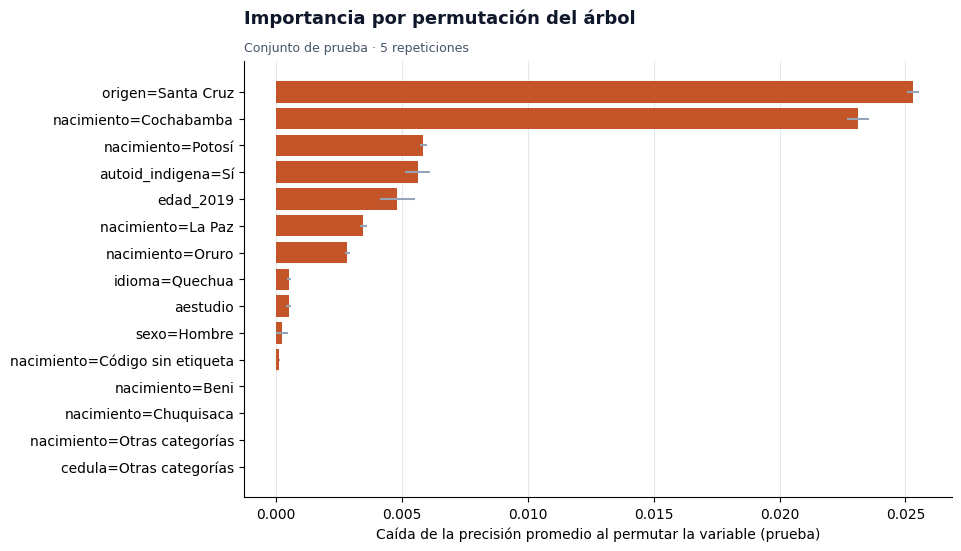

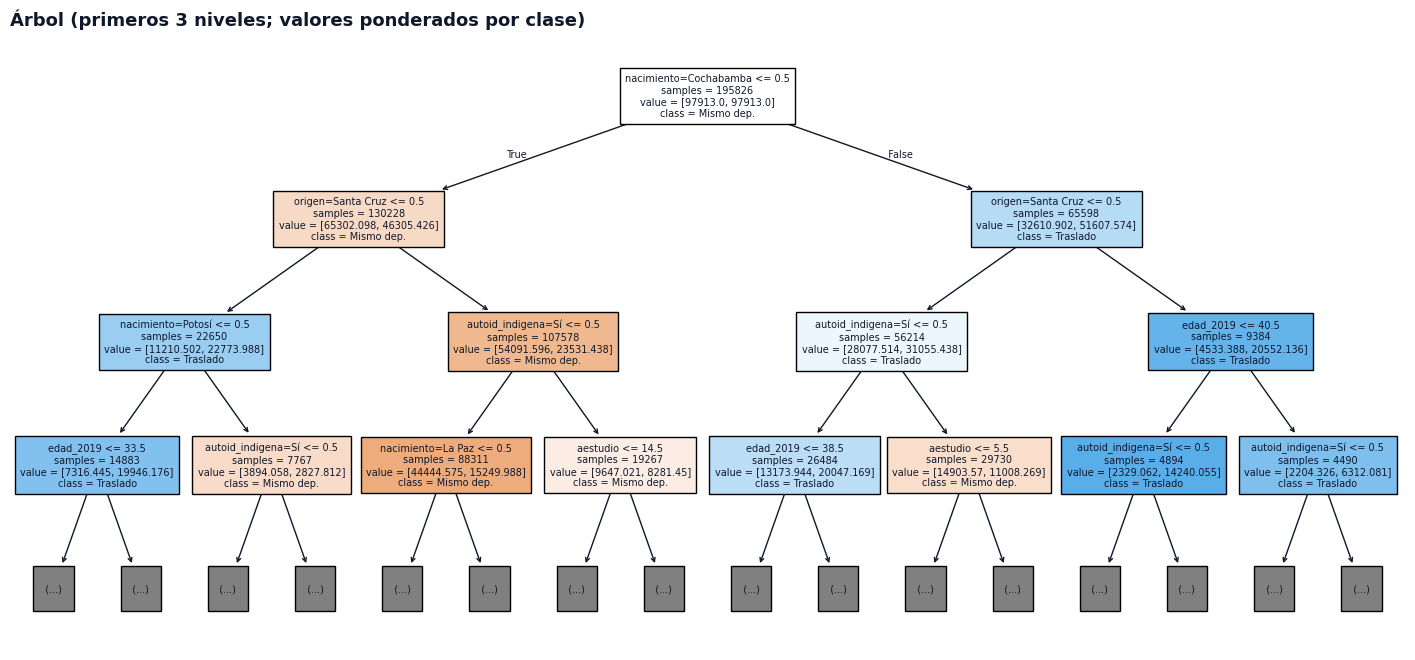

In [ ]:
X_tree_frame, _ = design_matrix(df, continuous_age=True)
tree_names = list(X_tree_frame.columns)
X_tree = X_tree_frame.to_numpy(dtype=float)

train_idx, test_idx = next(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
                           .split(X_tree, y, groups))
inner = [(train_idx[a], train_idx[b]) for a, b in
         StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
         .split(X_tree[train_idx], y[train_idx], groups[train_idx])]


def make_tree(depth, leaf):
    return DecisionTreeClassifier(max_depth=int(depth), min_samples_leaf=float(leaf),
                                  class_weight='balanced', random_state=SEED)


def cv_task(depth, leaf, fit_idx, val_idx):
    model = make_tree(depth, leaf).fit(X_tree[fit_idx], y[fit_idx])
    return average_precision_score(y[val_idx], model.predict_proba(X_tree[val_idx])[:, 1])


grid = [(d, l) for d in (3, 4, 5, 6) for l in (0.002, 0.005, 0.01)]
scores = np.array(Parallel(n_jobs=-1)(delayed(cv_task)(d, l, a, b) for d, l in grid for a, b in inner))
scores = scores.reshape(len(grid), len(inner))
cv = (pd.DataFrame(grid, columns=['max_depth', 'min_samples_leaf'])
      .assign(ap_media=scores.mean(axis=1), ap_ee=scores.std(axis=1, ddof=1) / np.sqrt(scores.shape[1])))
best = cv.loc[cv.ap_media.idxmax()]
chosen = (cv[cv.ap_media >= best.ap_media - best.ap_ee]
          .sort_values(['max_depth', 'min_samples_leaf'], ascending=[True, False]).iloc[0])
cv.to_csv(OUT / 'tree_cv_grid.csv', index=False)
display(cv.round(4))
print(f'Regla de un error estándar → max_depth={int(chosen.max_depth)}, min_samples_leaf={chosen.min_samples_leaf}')

tree = make_tree(chosen.max_depth, chosen.min_samples_leaf).fit(X_tree[train_idx], y[train_idx])
beta_train, _ = fit_logit(X[train_idx], y[train_idx])
y_test, g_test = y[test_idx], pd.factorize(groups[test_idx])[0]
p_tree = tree.predict_proba(X_tree[test_idx])[:, 1]
p_logit = expit(X[test_idx] @ beta_train)

rng = np.random.default_rng(SEED)
delta = np.empty((N_BOOT_TEST, 2))
for b in trange(N_BOOT_TEST):
    w = cluster_weights(rng, g_test)
    delta[b] = [roc_auc_score(y_test, p_logit, sample_weight=w) - roc_auc_score(y_test, p_tree, sample_weight=w),
                average_precision_score(y_test, p_logit, sample_weight=w)
                - average_precision_score(y_test, p_tree, sample_weight=w)]
d_lo, d_hi = np.percentile(delta, [2.5, 97.5], axis=0)

comparison = pd.DataFrame({
    'métrica': ['AUC-ROC', 'Precisión promedio (AP)'],
    'logit': [roc_auc_score(y_test, p_logit), average_precision_score(y_test, p_logit)],
    'árbol': [roc_auc_score(y_test, p_tree), average_precision_score(y_test, p_tree)],
    'diferencia_logit_menos_árbol': [
        roc_auc_score(y_test, p_logit) - roc_auc_score(y_test, p_tree),
        average_precision_score(y_test, p_logit) - average_precision_score(y_test, p_tree)],
    'diferencia_ic95_inf': d_lo, 'diferencia_ic95_sup': d_hi})
comparison.to_csv(OUT / 'logit_vs_tree_test.csv', index=False)
print(f'Conjunto de prueba: {len(test_idx):,} personas · prevalencia {100 * y_test.mean():.2f} % '
      '(AP sin información = prevalencia). El árbol usa class_weight="balanced": se compara solo el orden de riesgo. '
      f'IC 95 % bootstrap por vivienda con {N_BOOT_TEST} réplicas para la diferencia Logit − árbol.')
display(comparison.round(4))

perm = permutation_importance(tree, X_tree[test_idx], y_test, scoring='average_precision',
                              n_repeats=5, random_state=SEED, n_jobs=-1)
importance = (pd.DataFrame({'variable': tree_names, 'caida_AP': perm.importances_mean, 'ee': perm.importances_std})
              .sort_values('caida_AP', ascending=False))
importance.to_csv(OUT / 'tree_permutation_importance.csv', index=False)
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.4), layout='constrained')
ax.barh([fill(v, 36) for v in top.variable], top.caida_AP, xerr=top.ee, color=COLORS[1], ecolor='#94a3b8')
ax.grid(axis='x')
ax.set_xlabel('Caída de la precisión promedio al permutar la variable (prueba)')
heading(ax, 'Importancia por permutación del árbol', 'Conjunto de prueba · 5 repeticiones')
save_show(fig, 'tree_permutation_importance.png')

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, max_depth=3, feature_names=tree_names, class_names=['Mismo dep.', 'Traslado'],
          filled=True, impurity=False, fontsize=7, ax=ax)
ax.set_title('Árbol (primeros 3 niveles; valores ponderados por clase)', loc='left', fontweight='bold')
save_show(fig, 'tree_structure.png')

In [ ]:
def leaf_rules(model, feature_names):
    structure, rules = model.tree_, {}

    def walk(node, conditions):
        if structure.children_left[node] == -1:
            rules[node] = ' Y '.join(conditions) or 'Toda la población'
            return
        name, threshold = feature_names[structure.feature[node]], structure.threshold[node]
        if '=' in name:
            left, right = f'no {name}', name
        else:
            left, right = f'{name} ≤ {threshold:.1f}', f'{name} > {threshold:.1f}'
        walk(structure.children_left[node], [*conditions, left])
        walk(structure.children_right[node], [*conditions, right])

    walk(0, [])
    return rules


def wilson(events, n, z=1.96):
    p = events / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


def leaf_summary(idx):
    counts = (pd.DataFrame({'hoja': tree.apply(X_tree[idx]), 'y': y[idx]})
              .groupby('hoja').y.agg(n='size', eventos='sum'))
    counts['tasa'] = counts.eventos / counts.n
    return counts


test_leaves, train_leaves = leaf_summary(test_idx), leaf_summary(train_idx)
leaves = (test_leaves.join(train_leaves[['tasa']].rename(columns={'tasa': 'tasa_entrenamiento'}))
          .rename(columns={'tasa': 'tasa_prueba'}))
leaves['ic95_inf'], leaves['ic95_sup'] = wilson(leaves.eventos.to_numpy(), leaves.n.to_numpy())
leaves['lift'] = leaves.tasa_prueba / y_test.mean()
leaves['regla'] = pd.Series(leaf_rules(tree, tree_names))
leaves = leaves.sort_values('lift', ascending=False)
leaves.to_csv(OUT / 'tree_leaf_rules.csv')

pd.set_option('display.max_colwidth', None)
print(f'Prevalencia en prueba: {100 * y_test.mean():.2f} %. Tasas y lift calculados en el conjunto de prueba; '
      'solo se muestran hojas con al menos 30 eventos.')
stable = leaves[leaves.eventos >= 30]
display(stable[['regla', 'n', 'eventos', 'tasa_prueba', 'tasa_entrenamiento', 'ic95_inf', 'ic95_sup', 'lift']]
        .round(4).reset_index(drop=True))

picked = pd.concat([stable.head(6), stable.tail(3)]).drop_duplicates().iloc[::-1]
if len(picked):
    pos = np.arange(len(picked))
    fig, ax = plt.subplots(figsize=(11, .7 * len(picked) + 2), layout='constrained')
    ax.barh(pos, 100 * picked.tasa_prueba, color=COLORS[1],
            xerr=[100 * (picked.tasa_prueba - picked.ic95_inf), 100 * (picked.ic95_sup - picked.tasa_prueba)],
            ecolor='#94a3b8')
    ax.axvline(100 * y_test.mean(), color='#0f172a', ls='--', lw=.9, label='Prevalencia global')
    ax.set_yticks(pos, [fill(r, 60) for r in picked.regla], fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=1))
    ax.set_xlabel('Tasa de traslado observada en prueba (IC 95 % de Wilson)')
    ax.legend(loc='lower right')
    ax.grid(axis='x')
    heading(ax, 'Perfiles de mayor y menor traslado', 'Hojas del árbol con al menos 30 eventos')
    save_show(fig, 'tree_leaf_rates.png')

In [ ]:
def bootstrap_tree(depth, leaf, n_boot, seed):
    rng = np.random.default_rng(seed)
    importances = np.zeros((n_boot, X_tree.shape[1]))
    roots = []
    for b in trange(n_boot):
        w = cluster_weights(rng, groups)
        keep = w > 0
        model = make_tree(depth, leaf).fit(X_tree[keep], y[keep], sample_weight=w[keep])
        importances[b] = model.feature_importances_
        root = model.tree_.feature[0]
        roots.append(tree_names[root] if root >= 0 else 'Sin división')
    return importances, pd.Series(roots)


importances, roots = bootstrap_tree(chosen.max_depth, chosen.min_samples_leaf, N_BOOT_TREE, SEED)
stability = (pd.DataFrame({'variable': tree_names,
                           'importancia_media': importances.mean(axis=0),
                           'importancia_ic95_inf': np.percentile(importances, 2.5, axis=0),
                           'importancia_ic95_sup': np.percentile(importances, 97.5, axis=0),
                           'presente_en_arbol_pct': 100 * (importances > 0).mean(axis=0)})
             .sort_values('importancia_media', ascending=False))
stability.to_csv(OUT / 'tree_bootstrap_stability.csv', index=False)

print('Variable en la raíz del árbol (% de réplicas):')
display((100 * roots.value_counts(normalize=True)).round(1).to_frame('%'))
print(f'Importancia por impureza (sesgada hacia variables continuas), IC percentil 95 % y frecuencia de uso en {N_BOOT_TREE} réplicas:')
display(stability.head(15).round(4).reset_index(drop=True))

In [ ]:
print(con.execute('''SELECT count(DISTINCT i00) AS solo_i00,
                            count(DISTINCT concat_ws('|', idep, iprov, imun, i00)) AS clave_completa
                     FROM cohort''').fetchone())

report['model'] = {
    'analysis_scope': 'Modelo asociativo para traslado bilateral dentro del corredor Cochabamba ↔ Santa Cruz; no es un modelo causal ni un destino unidireccional.',
    'n_model_sample': int(len(df)),
    'n_bootstrap': int(N_BOOT),
    'bootstrap_interpretation': 'Bootstrap por vivienda con intervalos percentiles al 95 %. Los p-valores por signo son aproximaciones bootstrap y no sustituyen inferencia causal.',
    'covariate_timing': 'aestudio, idioma, autoidentificación y discapacidad son mediciones de 2024 y se interpretan solo como asociaciones contemporáneas.',
    'performance': records(perf),
    'coefficients': records(table),
    'logit_vs_tree_test_point_estimates': records(comparison),
    'tree_stability_exploratory': records(stability),
}
(OUT/'eda_validation_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
archive = shutil.make_archive(str(WORK/f'eda_corredor_bilateral_cbb_scz_{EDAD_MINIMA_2024}mas_outputs'), 'zip', OUT)
print('ZIP definitivo de resultados:', archive)
files.download(archive)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(1395772, 1395772)
ZIP definitivo de resultados: /content/cpv_corredor_cbb_sc/eda_corredor_bilateral_cbb_scz_25mas_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>